# Dengue Early-Warning for Sri Lankan Districts
### Predicting high-transmission dengue weeks two weeks ahead with a spline Generalized Additive Model (GAM), explained with its glass-box terms, SHAP and LIME

**Module:** Applied Machine Learning – final assignment

---
## 1. Problem statement

Dengue is Sri Lanka's biggest vector-borne disease. In this dataset, 174,687 cases were reported in 2017, the worst epidemic year, and 70,918 in 2023.
The Epidemiology Unit publishes **weekly case counts for the 26 RDHS areas** (25 districts plus Kalmunai).
Regional MOH offices and Public Health Inspectors respond to rising cases with vector-control work (fogging, larval source reduction and school/community clean-up drives).
These campaigns need **lead time**, because staff, insecticide and community mobilisation have to be scheduled in advance.

**ML task (binary classification):** at the end of report week *t*, using only information available that week, predict
whether a district's dengue cases in **week *t + 2*** will be **above that district's high-transmission threshold**.
The threshold is the district's 75th percentile of weekly cases over 2012–2021.

* Positive class (`high_risk = 1`): a week of unusually high transmission for that district.
* Two-week horizon: one week covers the reporting delay and one week covers mobilisation.

Each district has its own threshold, so Colombo (where 150 cases a week is normal) and Mullaitivu (where 5 a week is normal) are judged on their own scale.

## 2. Dataset: real Sri Lankan data

| | |
|---|---|
| **Source** | Epidemiology Unit, Ministry of Health Sri Lanka – *Weekly Epidemiological Report* (district dengue notifications) |
| **How it was collected** | The Epidemiology Unit publishes a *Weekly Epidemiological Report* (PDF) at epid.gov.lk with notified dengue cases per RDHS area. The `denguedatahub` package downloads these PDFs and extracts the tables into a tidy dataset |
| **Access** | Tidy version in the `denguedatahub` R package by Dr. Thiyanga S. Talagala, University of Sri Jayewardenepura (GitHub `thiyangt/denguedatahub`, object `srilanka_weekly_data`), exported to CSV |
| **Coverage** | 26 RDHS areas × weekly, 23 Dec 2006 – 17 May 2026 (26,311 rows) |
| **Columns** | `year`, `week`, `start.date`, `end.date`, `district`, `cases` |
| **Licence** | GPL-3 (denguedatahub); the underlying reports are public government publications |

This is a new problem for this module. It doesn't reuse the car or house price datasets that are common in other projects.

**Ethical data use.** The data are **aggregate weekly counts per health area**, published by the Ministry of Health for public surveillance. They contain no names, addresses, ages or any other individual-level or personal data, and no single patient can be identified from a district's weekly count. No consent issue arises, and the dataset is shared openly under its licence.

**Features and target (summary).** Raw inputs: district, week and weekly case count. From these, 19 engineered features (§6.4) describe the recent level, momentum, season and national situation. The target `high_risk` is 1 when cases in week *t + 2* exceed the district's 75th-percentile threshold. After cleaning there are 26,260 district-weeks: 21,528 for development (2007–2023) and 3,146 for testing (2024–2026).

## 3. Setup

In [1]:
import sys, json, time, warnings
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import seaborn as sns
import joblib

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (roc_auc_score, average_precision_score, f1_score, precision_score,
                             recall_score, balanced_accuracy_score, brier_score_loss,
                             roc_curve, precision_recall_curve, confusion_matrix, ConfusionMatrixDisplay)
from sklearn.calibration import calibration_curve
from xgboost import XGBClassifier
import pygam, optuna, shap, lime, lime.lime_tabular

from src.features import (load_raw, clean, fit_reference, build_features, split, time_series_folds,
                          FEATURES, FEATURE_DESCRIPTIONS, HORIZON, REFERENCE_YEARS)
from src.models import PersistenceBaseline, SplineGAMClassifier, CANDIDATE_INTERACTIONS   # the new algorithm

SEED = 42
np.random.seed(SEED)
FIG = ROOT / "reports" / "figures"; FIG.mkdir(parents=True, exist_ok=True)
MODELS = ROOT / "models"; MODELS.mkdir(exist_ok=True)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold"})

def savefig(name):
    plt.savefig(FIG / f"{name}.png", dpi=130, bbox_inches="tight")

print("numpy", np.__version__, "| pandas", pd.__version__, "| pygam (spline GAM)", pygam.__version__,
      "| shap", shap.__version__, "| optuna", optuna.__version__)

numpy 2.5.3 | pandas 2.3.3 | pygam (spline GAM) 0.12.0 | shap 0.54.1 | optuna 5.0.0


## 4. Load and inspect the raw data

In [2]:
raw = load_raw()
print("Shape:", raw.shape)
display(raw.head())
raw.info()

Shape: (26311, 7)


,year,week,start.date,end.date,district,cases,date
0,2006.0,52.0,12/23/2006,12/29/2006,Colombo,71.0,2006-12-23
1,2006.0,52.0,12/23/2006,12/29/2006,Gampaha,12.0,2006-12-23
2,2006.0,52.0,12/23/2006,12/29/2006,Kalutara,12.0,2006-12-23
3,2006.0,52.0,12/23/2006,12/29/2006,Kandy,20.0,2006-12-23
4,2006.0,52.0,12/23/2006,12/29/2006,Matale,4.0,2006-12-23


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 26311 entries, 0 to 26310
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   year        26311 non-null  float64       
 1   week        26311 non-null  float64       
 2   start.date  26311 non-null  object        
 3   end.date    26311 non-null  object        
 4   district    26311 non-null  object        
 5   cases       26311 non-null  float64       
 6   date        26311 non-null  datetime64[ns]
dtypes: datetime64[ns](1), float64(3), object(3)
memory usage: 1.4+ MB


In [3]:
print("Missing values per column:\n", raw.isna().sum().to_string())
print("\nDuplicate (year, week, district) rows:", raw.duplicated(["year", "week", "district"]).sum())
print("Date range:", raw["date"].min().date(), "->", raw["date"].max().date())
print("Districts:", raw["district"].nunique())
display(raw["cases"].describe().to_frame().T)
cnt = raw.groupby("district").size()
print("Rows per district (min/max):", cnt.min(), cnt.max(), "| short district:", cnt.idxmin())

Missing values per column:
 year          0
week          0
start.date    0
end.date      0
district      0
cases         0
date          0

Duplicate (year, week, district) rows: 0
Date range: 2006-12-23 -> 2026-05-11
Districts: 26


,count,mean,std,min,25%,50%,75%,max
cases,26311.0,31.681008,79.412352,0.0,2.0,9.0,29.0,2631.0


Rows per district (min/max): 1011 1012 | short district: Puttalam


In [4]:
# gaps between consecutive weeks in each district
gaps = raw.sort_values("date").groupby("district")["date"].diff().dt.days.value_counts().sort_index()
print("Days between consecutive reports:\n", gaps.to_string())

Days between consecutive reports:
 date
6.0        26
7.0     26206
8.0        26
9.0        26
14.0        1


**First observations**
* No `NaN`s and no duplicates. (The EDA below shows that the absence of `NaN`s is misleading: one district-year is recorded as zeros.) One district-week is completely missing (Puttalam, a 14-day gap). Report weeks are normally 7 days, with an occasional 6–9 day week at year boundaries.
* `cases` is a count that is **very right-skewed**: the median is 9, but the maximum is 2,631 (Colombo during the 2017 epidemic).
* The single 2006 week is a stub. The modelling period starts in 2007.

## 5. Exploratory data analysis

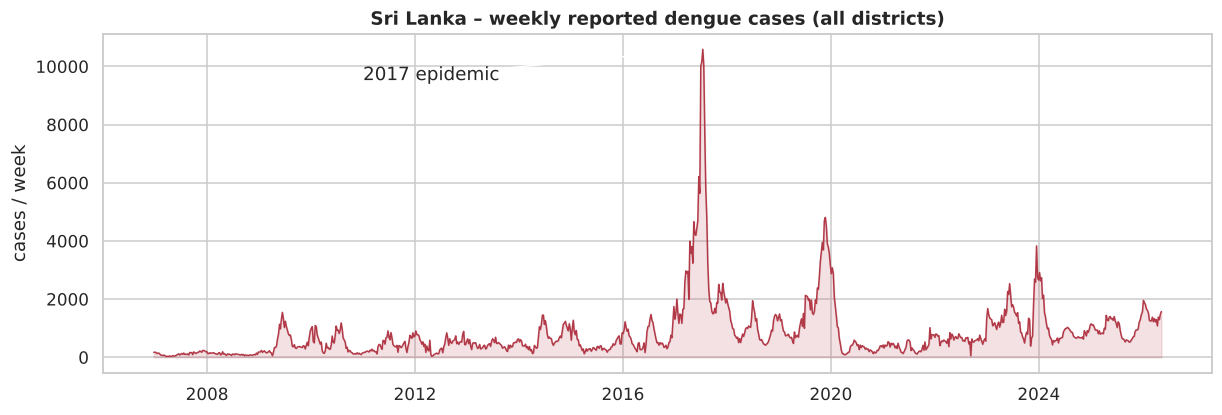

In [5]:
nat = raw.groupby("date")["cases"].sum()
fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(nat.index, nat.values, lw=1, color="#b23a48")
ax.fill_between(nat.index, nat.values, alpha=.15, color="#b23a48")
ax.set_title("Sri Lanka – weekly reported dengue cases (all districts)")
ax.set_ylabel("cases / week")
ax.annotate("2017 epidemic", xy=(pd.Timestamp("2017-07-01"), nat.max()), xytext=(pd.Timestamp("2011-01-01"), nat.max() * .9),
            arrowprops=dict(arrowstyle="->"))
savefig("eda_national_weekly"); plt.show()

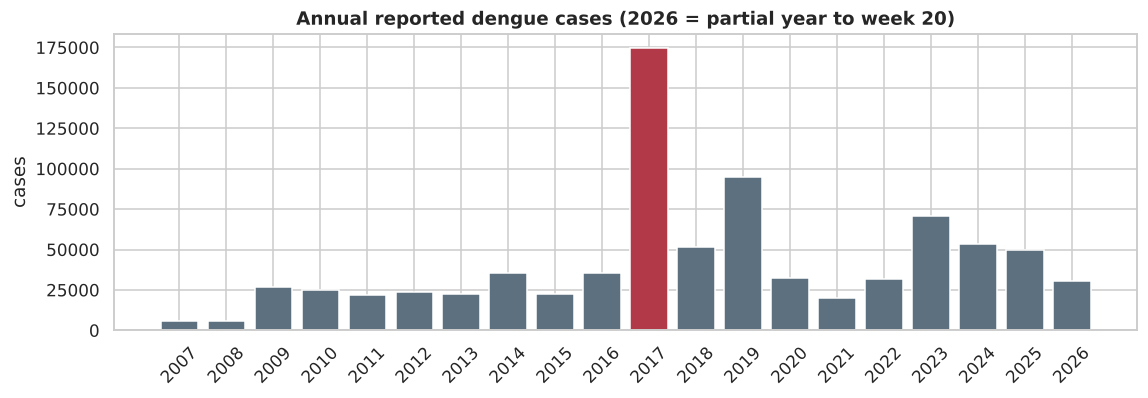

In [6]:
annual = raw[raw["year"] >= 2007].groupby("year")["cases"].sum()
fig, ax = plt.subplots(figsize=(12, 3.5))
bars = ax.bar(annual.index.astype(int).astype(str), annual.values, color=["#b23a48" if y == 2017 else "#5c7080" for y in annual.index])
ax.set_title("Annual reported dengue cases (2026 = partial year to week 20)"); ax.set_ylabel("cases")
plt.xticks(rotation=45); savefig("eda_annual"); plt.show()

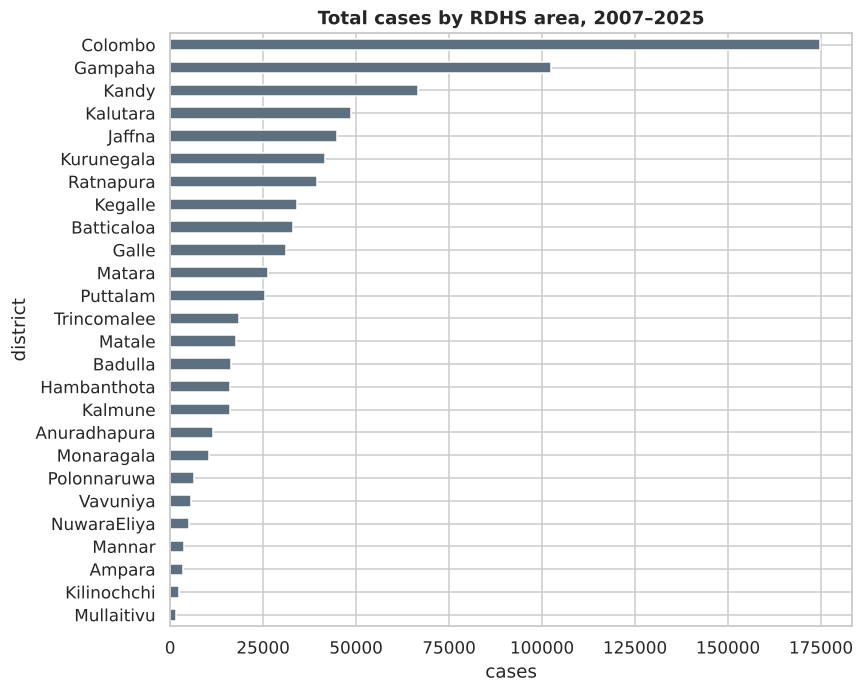

Colombo + Gampaha + Kalutara (Western Province) share: 40.5%


In [7]:
dist_tot = raw[raw["year"].between(2007, 2025)].groupby("district")["cases"].sum().sort_values()
fig, ax = plt.subplots(figsize=(8, 7))
dist_tot.plot.barh(ax=ax, color="#5c7080")
ax.set_title("Total cases by RDHS area, 2007–2025"); ax.set_xlabel("cases")
savefig("eda_district_totals"); plt.show()
print(f"Colombo + Gampaha + Kalutara (Western Province) share: {dist_tot[['Colombo','Gampaha','Kalutara']].sum() / dist_tot.sum():.1%}")

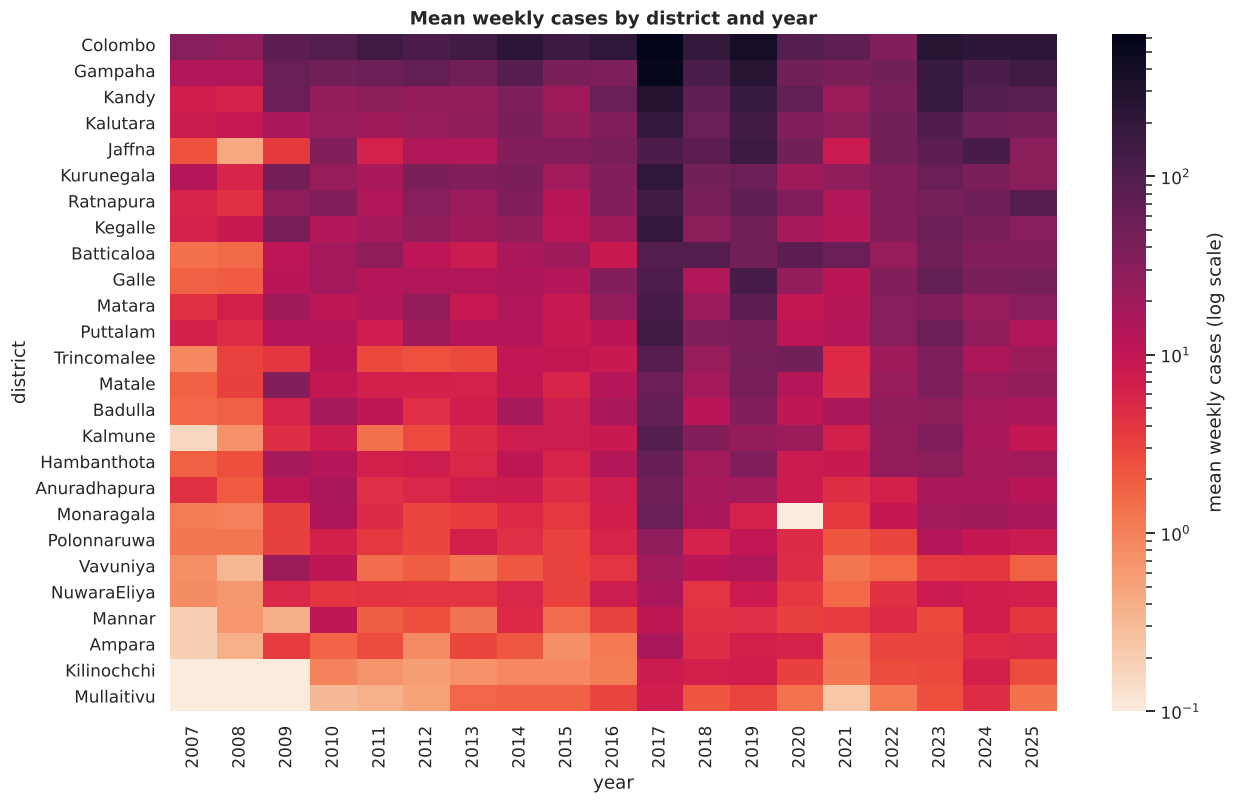

In [8]:
pivot = raw[raw["year"].between(2007, 2025)].pivot_table(index="district", columns="year", values="cases", aggfunc="mean")
pivot = pivot.loc[pivot.mean(axis=1).sort_values(ascending=False).index]
fig, ax = plt.subplots(figsize=(13, 8))
sns.heatmap(pivot + 0.1, norm=mcolors.LogNorm(), cmap="rocket_r", ax=ax, cbar_kws={"label": "mean weekly cases (log scale)"})
ax.set_xticklabels([int(float(t.get_text())) for t in ax.get_xticklabels()])
ax.set_title("Mean weekly cases by district and year")
savefig("eda_heatmap_district_year"); plt.show()

In [9]:
# Data-quality check suggested by the heatmap: district-years with (almost) no reported cases
yr_tot = raw[raw["year"].between(2009, 2025)].pivot_table(index="district", columns="year", values="cases", aggfunc="sum")
zero_years = yr_tot.stack()[lambda s: s == 0]
print("District-years with ZERO reported cases:\n", zero_years.to_string())
display(yr_tot.loc[["Monaragala"], [2018.0, 2019.0, 2020.0, 2021.0, 2022.0]])

District-years with ZERO reported cases:
 district     year  
Kilinochchi  2009.0    0.0
Monaragala   2020.0    0.0
Mullaitivu   2009.0    0.0


year,2018.0,2019.0,2020.0,2021.0,2022.0
district,,,,,
Monaragala,854.0,330.0,0.0,192.0,457.0


**Data-quality problem found.** **Monaragala reports 0 cases in every one of the 52 weeks of 2020**, compared with 330 in 2019 and 192 in 2021.
Dengue is endemic there and every neighbouring district reported cases that year, so this is a **reporting failure, with missing data recorded as zeros**.
It isn't a real absence of dengue. If left in, the model would learn that Monaragala can drop from normal levels to zero.
Handling (section 6.1): the year is set to missing, and the rows whose 52-week look-back or target week touches it are **excluded** from training and evaluation.

The near-zero counts for Kilinochchi and Mullaitivu in 2007–09 are different. Low numbers there are plausible (the end of the conflict period and small populations), and the neighbouring years are also low, so they're kept.

**Levels differ by two orders of magnitude between districts, and the whole country moves together in epidemic years** (2017, 2019, 2023).
A single threshold for all districts would make no sense. This is why the target and the features are defined **relative to each district's own normal level**.

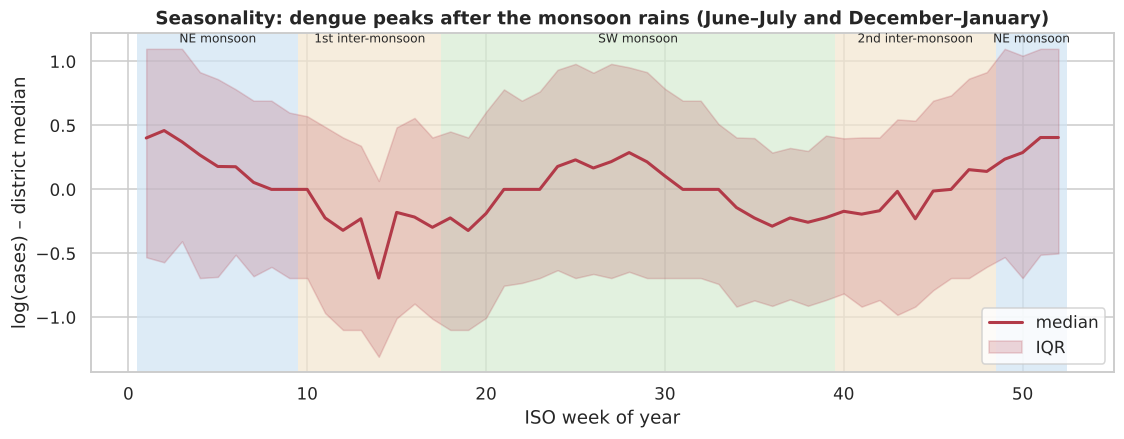

In [10]:
df = clean(raw)
df["woy"] = df["date"].dt.isocalendar().week.astype(int).clip(upper=52)
df["rel"] = np.log1p(df["cases"]) - np.log1p(df.groupby("district")["cases"].transform("median"))
season = df[df["date"].dt.year.between(2007, 2025)].groupby("woy")["rel"].agg(["median", lambda s: s.quantile(.25), lambda s: s.quantile(.75)])
season.columns = ["median", "q25", "q75"]
fig, ax = plt.subplots(figsize=(12, 4))
for (a, b, lab, c) in [(1, 9, "NE monsoon", "#cfe3f3"), (10, 17, "1st inter-monsoon", "#f3e6cf"), (18, 39, "SW monsoon", "#d6ecd2"), (40, 48, "2nd inter-monsoon", "#f3e6cf"), (49, 52, "NE monsoon", "#cfe3f3")]:
    ax.axvspan(a - .5, b + .5, color=c, alpha=.7, lw=0); ax.text((a + b) / 2, season["q75"].max() + .05, lab, ha="center", fontsize=8)
ax.plot(season.index, season["median"], color="#b23a48", lw=2, label="median")
ax.fill_between(season.index, season["q25"], season["q75"], color="#b23a48", alpha=.2, label="IQR")
ax.set_xlabel("ISO week of year"); ax.set_ylabel("log(cases) – district median")
ax.set_title("Seasonality: dengue peaks after the monsoon rains (June–July and December–January)"); ax.legend(loc="lower right")
savefig("eda_seasonality"); plt.show()

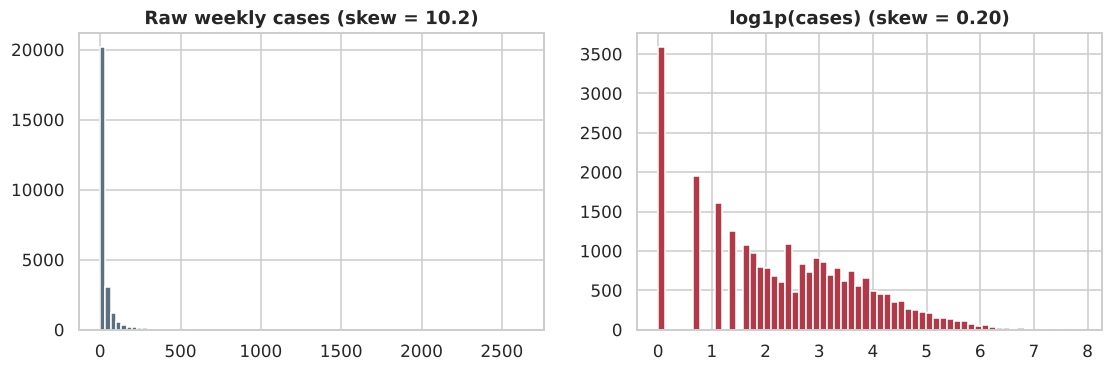

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
axes[0].hist(df["cases"], bins=80, color="#5c7080"); axes[0].set_title(f"Raw weekly cases (skew = {df['cases'].skew():.1f})")
axes[1].hist(np.log1p(df["cases"]), bins=60, color="#b23a48"); axes[1].set_title(f"log1p(cases) (skew = {np.log1p(df['cases']).skew():.2f})")
savefig("eda_distribution"); plt.show()

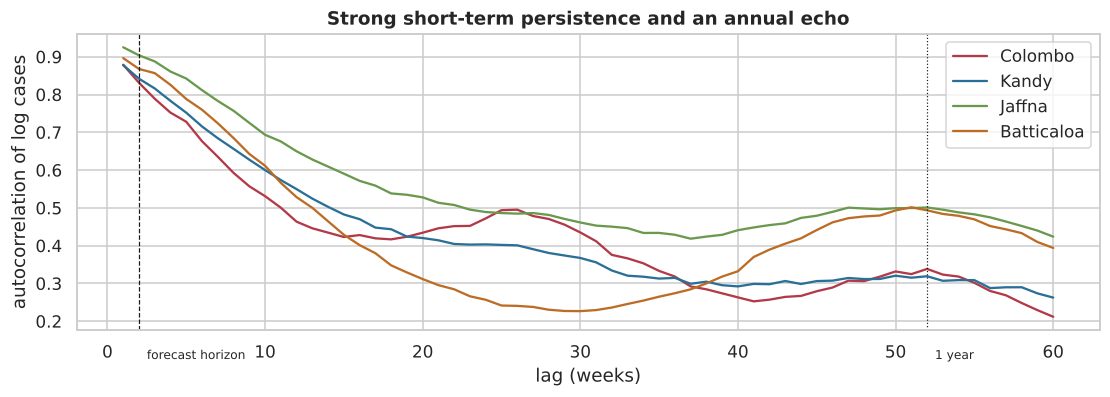

In [12]:
fig, ax = plt.subplots(figsize=(12, 3.5))
for d, c in [("Colombo", "#b23a48"), ("Kandy", "#2a6f97"), ("Jaffna", "#6a994e"), ("Batticaloa", "#bc6c25")]:
    s = np.log1p(df.loc[df["district"] == d, "cases"].reset_index(drop=True))
    ax.plot(range(1, 61), [s.autocorr(k) for k in range(1, 61)], label=d, color=c)
ax.axvline(HORIZON, ls="--", c="k", lw=.8); ax.text(HORIZON + .5, .1, "forecast horizon", fontsize=8)
ax.axvline(52, ls=":", c="k", lw=.8); ax.text(52.5, .1, "1 year", fontsize=8)
ax.set_xlabel("lag (weeks)"); ax.set_ylabel("autocorrelation of log cases"); ax.set_title("Strong short-term persistence and an annual echo")
ax.legend(); savefig("eda_autocorrelation"); plt.show()

**EDA takeaways that shape the modelling**
1. **Skewed counts.** A `log1p` transform makes the distribution near-symmetric (skew 3+ → ~0). All count features are expressed on the log scale.
2. **Strong autocorrelation.** The lag-2 autocorrelation is above 0.8, so recent weeks are the most informative. Recent lags, moving averages and growth rates are engineered as features. This also means a **persistence baseline** ("next is like now") will be hard to beat, so we report it.
3. **Monsoon seasonality and an annual echo.** Week-of-year sine/cosine terms, a seasonal norm and "same week last year" are added as features.
4. **Nationwide waves.** National growth and the share of districts above threshold are added as features.
5. **Structural change.** Levels after 2017 are higher than in 2007–2016, so a random split would leak the future. A **chronological split** with purging is used.

## 6. Preprocessing
### 6.1 Completing the time grid and imputing missing values

In [13]:
print("District-weeks after building the full grid:", len(df))
print("Imputed values (missing week + implausible values):", int(df["was_imputed"].sum()))
imp = df[df["was_imputed"] & ~df["implausible"]]
for _, r in imp.iterrows():
    ctx = df[(df["district"] == r["district"]) & (df["date"].between(r["date"] - pd.Timedelta(weeks=2), r["date"] + pd.Timedelta(weeks=2)))]
    display(ctx[["district", "date", "cases", "was_imputed"]])

District-weeks after building the full grid: 26260
Imputed values (missing week + implausible values): 23


,district,date,cases,was_imputed
23214,Puttalam,2026-01-26,26.0,False
23215,Puttalam,2026-02-02,24.0,False
23216,Puttalam,2026-02-09,25.0,True
23217,Puttalam,2026-02-16,26.0,False
23218,Puttalam,2026-02-23,30.0,False


In [14]:
print("Weeks flagged unreliable (zeros recorded for a missing year):", int(df["unreliable"].sum()),
      "->", df.loc[df["unreliable"], "district"].unique(), df.loc[df["unreliable"], "date"].dt.year.unique())

Weeks flagged unreliable (zeros recorded for a missing year): 52 -> ['Monaragala'] [2020]


In [15]:
# Isolated implausible weeks: < 10% of BOTH neighbouring weeks (or > 10x both), neighbours >= 30 cases
raw_lookup = raw.set_index(["district", "date"])["cases"]
imp_tbl = df[df["implausible"]][["district", "date"]].copy()
g_raw = raw.sort_values("date").groupby("district")
imp_tbl["reported"] = [raw_lookup.get((d, t)) for d, t in zip(imp_tbl["district"], imp_tbl["date"])]
imp_tbl["prev week"] = [raw_lookup.get((d, t - pd.Timedelta(weeks=1))) for d, t in zip(imp_tbl["district"], imp_tbl["date"])]
imp_tbl["next week"] = [raw_lookup.get((d, t + pd.Timedelta(weeks=1))) for d, t in zip(imp_tbl["district"], imp_tbl["date"])]
imp_tbl["imputed"] = df.loc[df["implausible"], "cases"].values
print(f"Implausible isolated values: {len(imp_tbl)}")
display(imp_tbl.sort_values("date").reset_index(drop=True))
wk = raw[raw["date"] == "2026-03-30"].set_index("district")["cases"]
print("Week of 30 Mar 2026 – national total is normal (", int(wk.sum()), ") but counts are shuffled between districts:")
print(wk[["Colombo", "Gampaha", "Kalutara", "Kilinochchi", "Mannar", "Matale", "NuwaraEliya"]].to_string())

Implausible isolated values: 22


,district,date,reported,prev week,next week,imputed
0,Vavuniya,2010-01-23,2.0,55.0,30.0,42.0
1,Batticaloa,2011-10-29,3.0,58.0,40.0,49.0
2,Colombo,2012-06-09,0.0,70.0,72.0,71.0
3,Colombo,2012-07-14,0.0,99.0,206.0,152.0
4,Colombo,2012-11-03,0.0,45.0,36.0,40.0
5,Puttalam,2013-02-02,0.0,45.0,33.0,39.0
6,Badulla,2015-01-03,2.0,41.0,38.0,40.0
7,Kandy,2016-06-04,1.0,55.0,92.0,74.0
8,Galle,2016-12-10,7.0,91.0,79.0,85.0
9,Vavuniya,2020-01-04,0.0,37.0,36.0,36.0


Week of 30 Mar 2026 – national total is normal ( 1217 ) but counts are shuffled between districts:
district
Colombo          9.0
Gampaha         10.0
Kalutara        10.0
Kilinochchi    117.0
Mannar          47.0
Matale         256.0
NuwaraEliya    113.0


**Three kinds of data problem, three treatments**
* **Isolated implausible weeks (22 values):** 15 are single weeks reported as 0–7 cases between two normal weeks (for example Colombo 70 → 0 → 72), which are missed reports recorded as zero.
  The other 7 all come from the **week of 30 March 2026**. That week's national total is normal, but the counts are **misaligned between districts**: Colombo, Gampaha and Kalutara show about 10 cases, while Kilinochchi, Mannar, Matale and Nuwara Eliya show 10–30 times their normal level.
  These values are set to missing and interpolated. The rule is conservative: both neighbouring weeks must be at least 30, so genuinely small counts in low-burden districts are never touched.
* **Isolated missing week (Puttalam):** filled by **linear interpolation within the district**. Weekly counts change smoothly, so this is better than a global mean or median (that would ignore the local trend) or dropping the row (that would break the lag features for the following weeks).
* **A whole missing year (Monaragala 2020, recorded as zeros):** a year of interpolated values would be invented data, so these weeks are set to missing and interpolated only to keep the time series continuous for the *other* rows' national features.
  Every district-week whose features or target depend on them (106 rows) is **excluded** from training, CV and testing, and from the threshold and seasonal reference.

### 6.2 Outliers
Very high counts (for example the 2017 epidemic) are **real epidemics, not errors**, and they are exactly what the model must recognise. They are **kept**. Their influence is controlled by
(i) the log transform, (ii) features expressed relative to each district's threshold, and (iii) tree-based models, which split on order and are robust to extreme values.

In [16]:
lg = np.log1p(df["cases"])
q1, q3 = lg.groupby(df["district"]).transform(lambda s: s.quantile(.25)), lg.groupby(df["district"]).transform(lambda s: s.quantile(.75))
out_mask = lg > q3 + 1.5 * (q3 - q1)
print(f"Weeks flagged as upper outliers by the 1.5×IQR rule on log scale: {out_mask.sum()} ({out_mask.mean():.1%})")
print("Share of them in 2017:", f"{(df.loc[out_mask, 'date'].dt.year == 2017).mean():.0%}")

Weeks flagged as upper outliers by the 1.5×IQR rule on log scale: 99 (0.4%)
Share of them in 2017: 73%


### 6.3 Target definition: district high-transmission thresholds
The threshold for each district is its **75th percentile of weekly cases over 2012–2021**. This is computed **inside the training period only**, so no test information leaks into the target definition. The same window gives each district's typical seasonal profile.

In [17]:
ref = fit_reference(df)
thr_tbl = pd.Series(ref["threshold"]).sort_values(ascending=False).rename("threshold (cases/week)")
display(thr_tbl.to_frame().T.round(0))

,Colombo,Gampaha,Kandy,Jaffna,Kalutara,Kurunegala,Ratnapura,Batticaloa,Kegalle,Matara,...,Matale,Anuradhapura,Monaragala,Polonnaruwa,Vavuniya,NuwaraEliya,Ampara,Mannar,Kilinochchi,Mullaitivu
threshold (cases/week),291.0,115.0,73.0,64.0,64.0,59.0,49.0,48.0,37.0,35.0,...,18.0,15.0,11.0,9.0,8.0,7.0,5.0,4.0,3.0,3.0


### 6.4 Feature engineering
All features use only data **up to week *t***. Counts are put on a log scale and **divided by the district threshold**, which turns them into log ratios, so the features have the same meaning in every district and in every era.

In [18]:
feat = build_features(df.drop(columns=["woy", "rel"]), ref)
print("Rows excluded because their window touches unreliable data:", int(feat["unreliable_window"].sum()))
display(pd.DataFrame({"feature": FEATURES, "description": [FEATURE_DESCRIPTIONS[f] for f in FEATURES]}))
display(feat[["district", "date", "cases", "threshold"] + FEATURES[:6] + ["target_cases", "high_risk"]].dropna().sample(5, random_state=SEED))

Rows excluded because their window touches unreliable data: 106


,feature,description
0,rel_now,This week's cases vs district threshold (log r...
1,rel_lag1,Cases 1 week ago vs threshold (log ratio)
2,rel_lag2,Cases 2 weeks ago vs threshold (log ratio)
3,rel_lag3,Cases 3 weeks ago vs threshold (log ratio)
4,rel_ma4,4-week average vs threshold (log ratio)
5,rel_ma8,8-week average vs threshold (log ratio)
6,rel_ma12,12-week average vs threshold (log ratio)
7,rel_ma52,52-week average vs threshold (log ratio)
8,growth_1w,Week-on-week growth (log)
9,growth_4w,Growth over 4 weeks (log)


,district,date,cases,threshold,rel_now,rel_lag1,rel_lag2,rel_lag3,rel_ma4,rel_ma8,target_cases,high_risk
23506,Ratnapura,2012-04-21,14.0,49.0,-1.203973,0.019803,-1.609438,-1.021651,-0.755023,-0.693147,17.0,0.0
12406,Kegalle,2012-06-30,13.0,37.0,-0.998529,0.212561,-3.637586,-3.637586,-0.880746,-1.347580,33.0,0.0
15684,Mannar,2017-04-01,43.0,4.0,2.174752,1.029619,0.875469,0.693147,1.386294,1.367366,25.0,1.0
16954,Matale,2022-03-26,3.0,18.0,-1.558145,-0.747214,-0.641854,-1.845827,-1.072637,-0.880746,6.0,0.0
12052,Kandy,2025-01-25,80.0,73.0,0.090384,-0.160930,0.052644,-0.114410,-0.027399,-0.048452,50.0,0.0


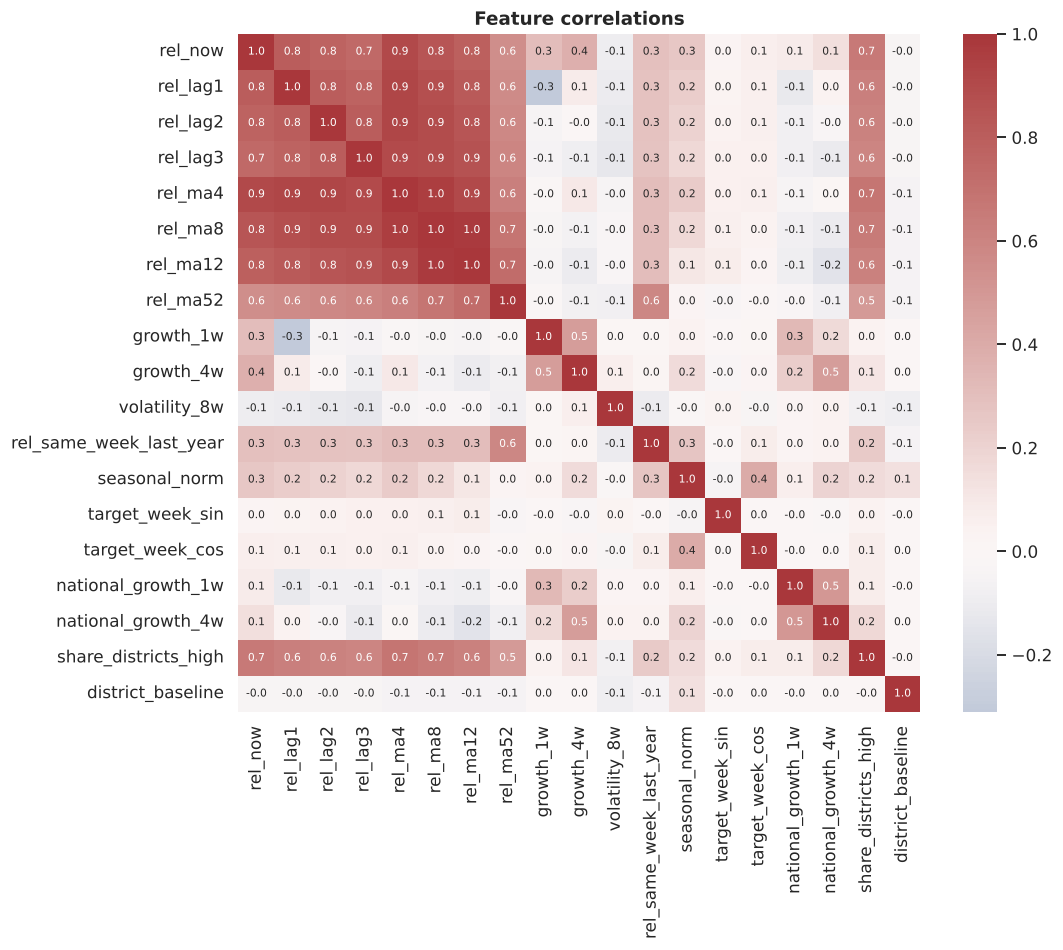

In [19]:
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(feat[FEATURES].dropna().corr(), cmap="vlag", center=0, ax=ax, annot=True, fmt=".1f", annot_kws={"size": 7})
ax.set_title("Feature correlations"); savefig("eda_feature_corr"); plt.show()

The lag and moving-average features are strongly correlated with each other, which is expected. For the spline GAM, correlated inputs can share an effect between them (called concurvity). The smoothness penalty shrinks redundant curves towards flat lines, which keeps the fit stable. The logistic-regression comparison model uses regularisation for the same reason.

### 6.5 Chronological train / validation / test split (with purging)
* **Train:** report weeks in 2007–2021 · **Validation:** 2022–2023 · **Test:** 2024 → May 2026 (never used for any decision)
* Rows whose 2-week-ahead target falls in the next period are **purged**, so no label crosses a boundary.
* Hyperparameters are tuned on the **development set** (train + validation, 2007–2023) using **expanding-window time-series cross-validation** with validation years 2019, 2020, 2021, 2022 and 2023.
* **One data point is held out entirely** (the latest Colombo week with a known outcome) for the inference demo in section 12.

In [20]:
train, valid, test = split(feat)
dev = pd.concat([train, valid]).reset_index(drop=True)
test = test.reset_index(drop=True)

# hold out a single unseen data point for the final inference demo
ho_idx = test[(test["district"] == "Colombo")]["date"].idxmax()
holdout = test.loc[[ho_idx]].copy()
test = test.drop(index=ho_idx).reset_index(drop=True)
holdout.to_csv(ROOT / "data" / "holdout_sample.csv", index=False)

X_dev, y_dev = dev[FEATURES], dev["high_risk"].astype(int).values
X_test, y_test = test[FEATURES], test["high_risk"].astype(int).values
folds = time_series_folds(dev)
oof_idx = np.concatenate([va for _, va in folds])

summary = pd.DataFrame({
    "period": ["train 2007–21", "valid 2022–23", "test 2024–26", "hold-out point"],
    "rows": [len(train), len(valid), len(test), 1],
    "positive rate": [train["high_risk"].mean(), valid["high_risk"].mean(), test["high_risk"].mean(), holdout["high_risk"].mean()],
})
display(summary.round(3))
print("CV folds (train rows, validation rows):", [(len(a), len(b)) for a, b in folds])
print("Hold-out point:", holdout[["district", "date", "target_date", "cases", "target_cases", "high_risk"]].to_dict("records"))

,period,rows,positive rate
0,train 2007–21,18850,0.197
1,valid 2022–23,2678,0.383
2,test 2024–26,3145,0.344
3,hold-out point,1,1.000


CV folds (train rows, validation rows): [(14898, 1300), (16250, 1250), (17550, 1250), (18850, 1326), (20176, 1300)]
Hold-out point: [{'district': 'Colombo', 'date': Timestamp('2026-04-27 00:00:00'), 'target_date': Timestamp('2026-05-11 00:00:00'), 'cases': 300.0, 'target_cases': 308.0, 'high_risk': 1.0}]


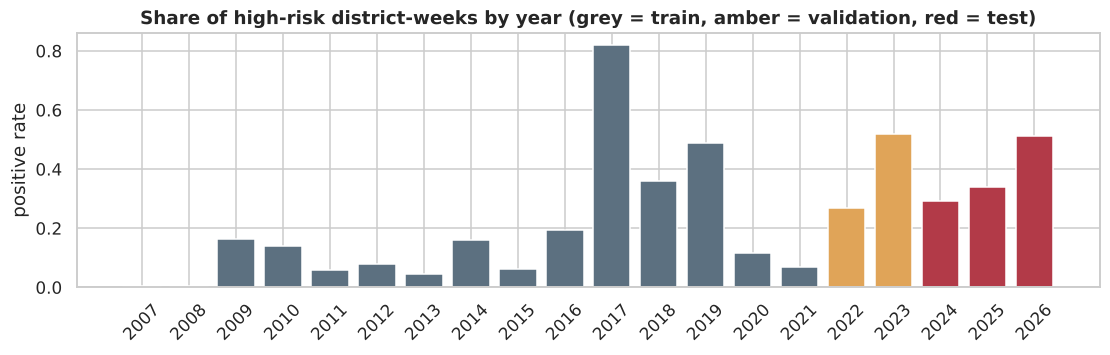

In [21]:
rate = feat.dropna(subset=["high_risk"]).groupby(feat["date"].dt.year)["high_risk"].mean()
fig, ax = plt.subplots(figsize=(12, 3))
ax.bar(rate.index.astype(str), rate.values, color=["#5c7080" if y <= 2021 else "#e0a458" if y <= 2023 else "#b23a48" for y in rate.index])
ax.set_title("Share of high-risk district-weeks by year (grey = train, amber = validation, red = test)"); ax.set_ylabel("positive rate")
plt.xticks(rotation=45); savefig("eda_class_balance"); plt.show()

The classes are imbalanced in training (about 20% positive) and the positive rate **shifts over time** (82% in 2017, 7% in 2021). Because of this:
* **PR-AUC** (average precision) is the main tuning and selection metric. Unlike accuracy, it focuses on the positive class.
* Class weighting is **tuned** for the standard models that support it, and every model's decision threshold is chosen on out-of-fold predictions.
* The decision threshold is chosen on the out-of-fold CV predictions, not left at 0.5.

### 6.6 Scaling
The spline GAM places its spline knots over each feature's own range, and the tree models only use split points, so neither depends on feature scale and both use the raw engineered features. Logistic regression and k-NN (which is distance-based) use a `StandardScaler` **inside a Pipeline**, which is fitted on each training fold only, so there's no leakage.

In [22]:
sc = StandardScaler().fit(X_dev)
print(pd.DataFrame({"mean before": X_dev.mean(), "std before": X_dev.std(),
                    "mean after": sc.transform(X_dev).mean(0), "std after": sc.transform(X_dev).std(0)}).round(2).head(8))

          mean before  std before  mean after  std after
rel_now         -0.85        1.16        -0.0        1.0
rel_lag1        -0.85        1.15         0.0        1.0
rel_lag2        -0.85        1.15        -0.0        1.0
rel_lag3        -0.86        1.15        -0.0        1.0
rel_ma4         -0.75        1.04         0.0        1.0
rel_ma8         -0.72        1.00         0.0        1.0
rel_ma12        -0.69        0.97         0.0        1.0
rel_ma52        -0.57        0.84        -0.0        1.0


## 7. Evaluation helpers and baselines

In [23]:
def metrics(y, p, thr=0.5):
    yhat = (p >= thr).astype(int)
    return {"ROC-AUC": roc_auc_score(y, p), "PR-AUC": average_precision_score(y, p),
            "F1": f1_score(y, yhat), "Precision": precision_score(y, yhat, zero_division=0),
            "Recall": recall_score(y, yhat), "Bal. acc.": balanced_accuracy_score(y, yhat), "Brier": brier_score_loss(y, p)}

def cv_oof(model, X=X_dev, y=y_dev, folds=folds):
    """Fit on each expanding window and return pooled out-of-fold probabilities + per-fold PR-AUC."""
    preds, scores = [], []
    for tr, va in folds:
        m = clone(model).fit(X.iloc[tr], y[tr])
        p = m.predict_proba(X.iloc[va])[:, 1]
        preds.append(p); scores.append(average_precision_score(y[va], p))
    return np.concatenate(preds), np.array(scores)

def best_threshold(y, p):
    grid = np.linspace(0.05, 0.95, 91)
    f1s = [f1_score(y, p >= t) for t in grid]
    return float(grid[int(np.argmax(f1s))])

y_oof = y_dev[oof_idx]
fold_year = np.concatenate([[y] * len(va) for y, (_, va) in zip(range(2019, 2024), folds)])

In [24]:
baselines = {
    "Persistence (next = now)": PersistenceBaseline(),
}
cv_rows, oof_store = [], {}
for name, m in baselines.items():
    p, s = cv_oof(m); oof_store[name] = p
    cv_rows.append({"model": name, "stage": "baseline", "CV PR-AUC": s.mean(), "CV PR-AUC sd": s.std(), **{f"F1 {k}": v for k, v in [("@0.5", f1_score(y_oof, p >= .5))]}})
# seasonal naive: was the target week above threshold last year?
p_sn = (X_dev["rel_same_week_last_year"].values[oof_idx] > 0).astype(float); oof_store["Seasonal naive (last year)"] = p_sn
cv_rows.append({"model": "Seasonal naive (last year)", "stage": "baseline",
                "CV PR-AUC": np.mean([average_precision_score(y_oof[fold_year == y], p_sn[fold_year == y]) for y in range(2019, 2024)]),
                "CV PR-AUC sd": np.std([average_precision_score(y_oof[fold_year == y], p_sn[fold_year == y]) for y in range(2019, 2024)]),
                "F1 @0.5": f1_score(y_oof, p_sn >= .5)})
display(pd.DataFrame(cv_rows).round(3))

,model,stage,CV PR-AUC,CV PR-AUC sd,F1 @0.5
0,Persistence (next = now),baseline,0.577,0.159,0.742
1,Seasonal naive (last year),baseline,0.301,0.199,0.328


## 8. The new algorithm: spline Generalized Additive Model (GAM)

**What it is.** A Generalized Additive Model (Hastie & Tibshirani, 1986/1990) replaces each linear term of a logistic model with a **smooth, learned function** of that feature. Here each function is a **penalised B-spline (P-spline)** (Eilers & Marx, 1996), fitted with the `pyGAM` library (Servén & Brummitt, 2018):

$$\text{logit}\,P(y=1\mid x) \;=\; \beta_0 \;+\; \sum_{j} f_j(x_j) \;+\; \sum_{(i,j)\in\mathcal{I}} f_{ij}(x_i, x_j), \qquad f_j(x) = \sum_{k=1}^{K} \beta_{jk}\, B_k(x)$$

* **Basis expansion.** Each feature's range is covered by $K$ overlapping cubic B-spline "bumps" $B_k$ (`n_splines` = $K$). A weighted sum of the bumps can follow any smooth curve.
* **Smoothness penalty.** Too many bumps would overfit, so the fit maximises a *penalised* likelihood: $\;\ell(\beta) - \lambda \sum_j \beta_j^\top D^\top D\, \beta_j$, where $D$ takes second differences of neighbouring coefficients. Large $\lambda$ (`lam`) forces near-straight lines; small $\lambda$ allows wiggles. $\lambda$ trades bias against variance and is tuned by cross-validation.
* **Fitting: penalised iteratively re-weighted least squares (PIRLS).** Each iteration solves a weighted, penalised least-squares problem, the same Newton method used for logistic regression, but on the expanded spline basis. The optimum is unique (convex), so there's no randomness and no ensemble.
* **Interactions (optional).** A **tensor-product spline** $f_{ij}(x_i,x_j)$ is a smooth 2-D surface for a chosen pair of features. Tuning decides how many candidate pairs to add (0–3).
* **Uncertainty.** Because it is a penalised regression, pyGAM gives a **95% confidence band** for every learned curve.

Because the final model is a **sum of 1-D curves (and a few 2-D surfaces)**, every prediction decomposes *exactly* into per-feature contributions. It's a **glass-box** model, unlike black-box ensembles that need post-hoc explainers.

**How it differs from the standard models taught in the module** (these are used below only as comparisons):

| | Logistic regression | Decision tree | k-NN | Random Forest / XGBoost | **Spline GAM (new)** |
|---|---|---|---|---|---|
| Model form | linear sum of features | one tree | stored training examples | many trees on *all* features, averaged or boosted | **additive sum of smooth spline curves + optional 2-D spline surfaces** |
| Non-linear effects | no (unless engineered) | yes, as coarse steps | yes, implicitly | yes, as many steps | **yes, as a smooth curve per feature** |
| How it is fitted | maximum likelihood (IRLS) | greedy splitting | no fitting (lazy) | greedy splitting, bagging / boosting | **penalised likelihood (PIRLS) with a smoothness penalty** |
| Interactions | none | yes, unrestricted | implicit | yes, unrestricted (hard to see) | **only chosen pairs, each visible as a surface** |
| Interpretability | coefficients | readable only when shallow | none (lazy) | needs SHAP/LIME (approximate) | **exact curves with confidence bands; exact local contributions** |
| Needs scaling | yes | no | yes (distance-based) | no | **no** |

It is the natural middle ground between logistic regression (too rigid: one straight line per feature) and tree ensembles (flexible but opaque).

**Why a spline GAM for this problem.** The EDA showed smooth threshold-like effects (risk rises steeply as a district nears its threshold), seasonality, and collinear lag features. Smooth curves suit these, and the smoothness penalty stops the model from chasing noise in small districts. For a **public-health early warning**, officials must be able to **see and trust *why*** a district is flagged. A GAM shows the exact curve behind each feature's effect, with uncertainty, so every alert can be audited. The comparison below tests how much accuracy this costs.

## 9. Models with default hyperparameters (reference point only)
The new algorithm (spline GAM) and five **standard models** (logistic regression, decision tree, k-NN, Random Forest, XGBoost) are first run with library defaults. This shows how much tuning matters. Logistic regression and k-NN use a `StandardScaler` inside a pipeline.

In [25]:
default_models = {
    "Spline GAM (new algorithm)": SplineGAMClassifier(),   # pyGAM defaults: 20 splines, lam = 0.6, no interactions
    "Logistic Regression": Pipeline([("scale", StandardScaler()), ("clf", LogisticRegression(max_iter=1000))]),
    "Decision Tree": DecisionTreeClassifier(random_state=SEED),
    "k-NN": Pipeline([("scale", StandardScaler()), ("clf", KNeighborsClassifier())]),
    "Random Forest": RandomForestClassifier(random_state=SEED, n_jobs=-1),
    "XGBoost": XGBClassifier(random_state=SEED, n_jobs=-1, eval_metric="logloss"),
}
default_scores = {}
for name, m in default_models.items():
    t0 = time.time(); p, s = cv_oof(m)
    default_scores[name] = s.mean()
    cv_rows.append({"model": name, "stage": "default", "CV PR-AUC": s.mean(), "CV PR-AUC sd": s.std(), "F1 @0.5": f1_score(y_oof, p >= .5)})
    print(f"{name:22s} default CV PR-AUC = {s.mean():.4f}  ({time.time()-t0:.0f}s)")

Spline GAM (new algorithm) default CV PR-AUC = 0.7744  (42s)


Logistic Regression    default CV PR-AUC = 0.7782  (0s)


Decision Tree          default CV PR-AUC = 0.4868  (1s)


k-NN                   default CV PR-AUC = 0.6515  (0s)


Random Forest          default CV PR-AUC = 0.7720  (10s)


XGBoost                default CV PR-AUC = 0.7497  (1s)


## 10. Hyperparameter tuning (Optuna, Bayesian TPE search, time-series CV)
**Objective:** mean PR-AUC over the five expanding-window folds. The spline GAM gets the largest budget because it's the proposed model. The standard models are tuned too, so the comparison is fair.

**Spline GAM search space and why:**
* `lam` (0.01–1000, log): the smoothness penalty, the most important setting. Small values let curves bend to follow noise; large values flatten them towards straight lines.
* `n_splines` (5–25): how many B-spline basis functions per feature, i.e. the maximum flexibility before the penalty is applied.
* `spline_order` (2 or 3): quadratic or cubic pieces.
* `n_interactions` (0–3): how many tensor-product surfaces to add, taken in order from three candidate pairs chosen from the EDA and domain knowledge: `rel_now × district_baseline` (is a high week more persistent in big districts?), `target_week_sin × share_districts_high` (does a national wave matter more in some seasons?) and `rel_ma4 × growth_4w` (level × momentum). 0 gives a purely additive model, the most interpretable.

In [26]:
optuna.logging.set_verbosity(optuna.logging.WARNING)

def gam_space(t):
    return SplineGAMClassifier(lam=t.suggest_float("lam", 1e-2, 1e3, log=True),
                               n_splines=t.suggest_int("n_splines", 5, 25),
                               spline_order=t.suggest_categorical("spline_order", [2, 3]),
                               interactions=CANDIDATE_INTERACTIONS[:t.suggest_int("n_interactions", 0, 3)])

def lr_space(t):
    return Pipeline([("scale", StandardScaler()), ("clf", LogisticRegression(
        C=t.suggest_float("C", 1e-3, 10, log=True), l1_ratio=t.suggest_categorical("l1_ratio", [0.0, 0.5, 1.0]),
        solver="saga", class_weight=t.suggest_categorical("class_weight", [None, "balanced"]), max_iter=3000))])

def dt_space(t):
    return DecisionTreeClassifier(max_depth=t.suggest_int("max_depth", 2, 14),
                                  min_samples_leaf=t.suggest_int("min_samples_leaf", 5, 300, log=True),
                                  criterion=t.suggest_categorical("criterion", ["gini", "entropy"]),
                                  class_weight=t.suggest_categorical("class_weight", [None, "balanced"]), random_state=SEED)

def knn_space(t):
    return Pipeline([("scale", StandardScaler()), ("clf", KNeighborsClassifier(
        n_neighbors=t.suggest_int("n_neighbors", 5, 300, log=True),
        weights=t.suggest_categorical("weights", ["uniform", "distance"]), p=t.suggest_categorical("p", [1, 2])))])

def rf_space(t):
    return RandomForestClassifier(
        n_estimators=t.suggest_int("n_estimators", 200, 400, step=100), max_depth=t.suggest_int("max_depth", 4, 16),
        min_samples_leaf=t.suggest_int("min_samples_leaf", 5, 100, log=True),
        max_features=t.suggest_categorical("max_features", ["sqrt", 0.3, 0.5]),
        max_samples=t.suggest_float("max_samples", 0.3, 0.9), n_jobs=-1, random_state=SEED)

def xgb_space(t):
    return XGBClassifier(
        n_estimators=t.suggest_int("n_estimators", 200, 800, step=50), learning_rate=t.suggest_float("learning_rate", 0.01, 0.2, log=True),
        max_depth=t.suggest_int("max_depth", 2, 7), min_child_weight=t.suggest_float("min_child_weight", 1, 30, log=True),
        subsample=t.suggest_float("subsample", 0.5, 1.0), colsample_bytree=t.suggest_float("colsample_bytree", 0.4, 1.0),
        reg_lambda=t.suggest_float("reg_lambda", 1e-2, 20, log=True), scale_pos_weight=t.suggest_float("scale_pos_weight", 1, 3),
        tree_method="hist", eval_metric="logloss", n_jobs=-1, random_state=SEED)

spaces = {"Spline GAM (new algorithm)": (gam_space, 25), "Logistic Regression": (lr_space, 10), "Decision Tree": (dt_space, 20),
          "k-NN": (knn_space, 15), "Random Forest": (rf_space, 10), "XGBoost": (xgb_space, 20)}

studies, tuned = {}, {}
for name, (space, n_trials) in spaces.items():
    t0 = time.time()
    study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=SEED), study_name=name)
    study.optimize(lambda t: cv_oof(space(t))[1].mean(), n_trials=n_trials)
    studies[name] = study
    tuned[name] = space(optuna.trial.FixedTrial(study.best_params))
    print(f"{name:22s} best CV PR-AUC = {study.best_value:.4f}  (default {default_scores[name]:.4f}) | {n_trials} trials, {time.time()-t0:.0f}s")

best_params = {n: s.best_params for n, s in studies.items()}
json.dump(best_params, open(MODELS / "best_params.json", "w"), indent=2, default=str)
best_params

Spline GAM (new algorithm) best CV PR-AUC = 0.7836  (default 0.7744) | 25 trials, 734s


Logistic Regression    best CV PR-AUC = 0.7789  (default 0.7782) | 10 trials, 9s


Decision Tree          best CV PR-AUC = 0.7554  (default 0.4868) | 20 trials, 14s


k-NN                   best CV PR-AUC = 0.7671  (default 0.6515) | 15 trials, 15s


Random Forest          best CV PR-AUC = 0.7845  (default 0.7720) | 10 trials, 140s


XGBoost                best CV PR-AUC = 0.7872  (default 0.7497) | 20 trials, 39s


{'Spline GAM (new algorithm)': {'lam': 508.907343010699,
  'n_splines': 16,
  'spline_order': 2,
  'n_interactions': 1},
 'Logistic Regression': {'C': 0.06672367170464207,
  'l1_ratio': 0.0,
  'class_weight': None},
 'Decision Tree': {'max_depth': 13,
  'min_samples_leaf': 137,
  'criterion': 'entropy',
  'class_weight': 'balanced'},
 'k-NN': {'n_neighbors': 267, 'weights': 'distance', 'p': 1},
 'Random Forest': {'n_estimators': 300,
  'max_depth': 7,
  'min_samples_leaf': 24,
  'max_features': 0.3,
  'max_samples': 0.8921321619603104},
 'XGBoost': {'n_estimators': 350,
  'learning_rate': 0.05082341959721458,
  'max_depth': 2,
  'min_child_weight': 15.30883741573138,
  'subsample': 0.5372753218398854,
  'colsample_bytree': 0.9921321619603104,
  'reg_lambda': 3.5416296712651336,
  'scale_pos_weight': 1.3974313630683448}}

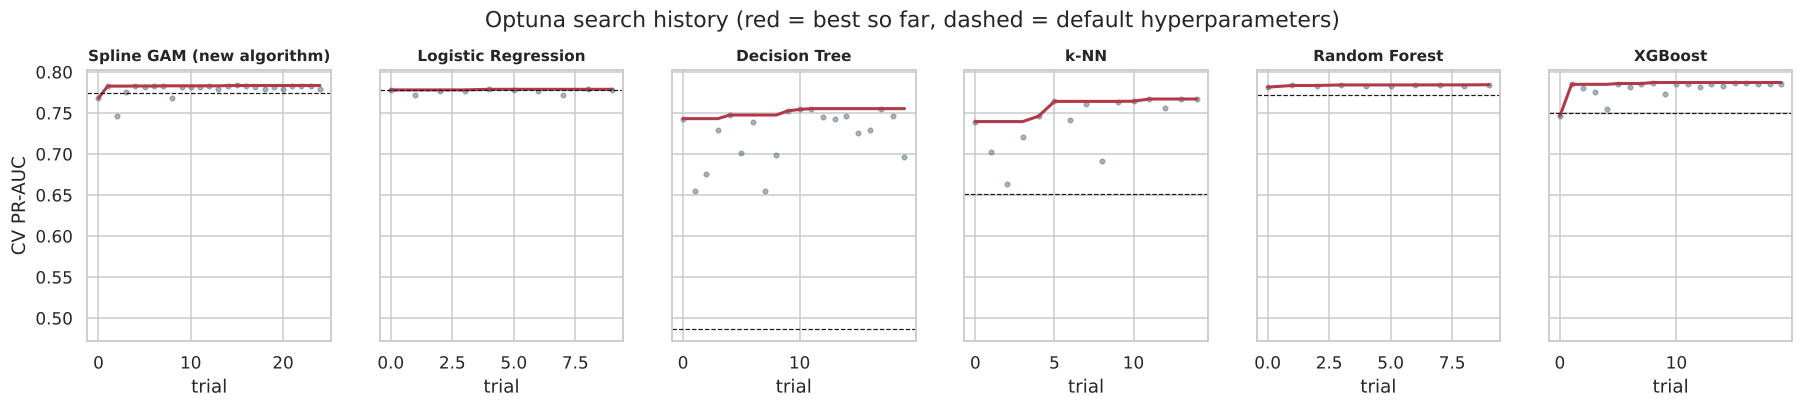

In [27]:
fig, axes = plt.subplots(1, len(studies), figsize=(20, 3.2), sharey=True)
for ax, (name, st) in zip(axes, studies.items()):
    v = [t.value for t in st.trials]
    ax.plot(v, "o", ms=3, alpha=.5, color="#5c7080"); ax.plot(np.maximum.accumulate(v), color="#b23a48", lw=2)
    ax.axhline(default_scores[name], ls="--", c="k", lw=.8); ax.set_title(name, fontsize=10); ax.set_xlabel("trial")
axes[0].set_ylabel("CV PR-AUC"); fig.suptitle("Optuna search history (red = best so far, dashed = default hyperparameters)", y=1.05)
savefig("tuning_history"); plt.show()

In [28]:
try:
    imp = optuna.importance.get_param_importances(studies["Spline GAM (new algorithm)"])
    display(pd.Series(imp).round(3).to_frame("importance for spline GAM CV PR-AUC"))
except Exception as e:
    print(e)

,importance for spline GAM CV PR-AUC
lam,0.423
n_interactions,0.323
n_splines,0.249
spline_order,0.005


## 11. Tuned models: cross-validated comparison and decision thresholds

,model,stage,CV PR-AUC,CV PR-AUC sd,F1 @0.5
0,Persistence (next = now),baseline,0.5771,0.1585,0.7420
1,Seasonal naive (last year),baseline,0.3013,0.1992,0.3276
2,Spline GAM (new algorithm),default,0.7744,0.1450,0.7179
3,Logistic Regression,default,0.7782,0.1437,0.7249
4,Decision Tree,default,0.4868,0.1676,0.6621
5,k-NN,default,0.6515,0.1852,0.6755
6,Random Forest,default,0.7720,0.1488,0.7370
7,XGBoost,default,0.7497,0.1672,0.7252
8,Spline GAM (new algorithm),tuned,0.7836,0.1397,0.7305
9,Logistic Regression,tuned,0.7789,0.1419,0.7192


stage,default,tuned,gain
model,,,
XGBoost,0.7497,0.7872,0.0375
Random Forest,0.7720,0.7845,0.0125
Spline GAM (new algorithm),0.7744,0.7836,0.0091
Logistic Regression,0.7782,0.7789,0.0007
k-NN,0.6515,0.7671,0.1155
Decision Tree,0.4868,0.7554,0.2686


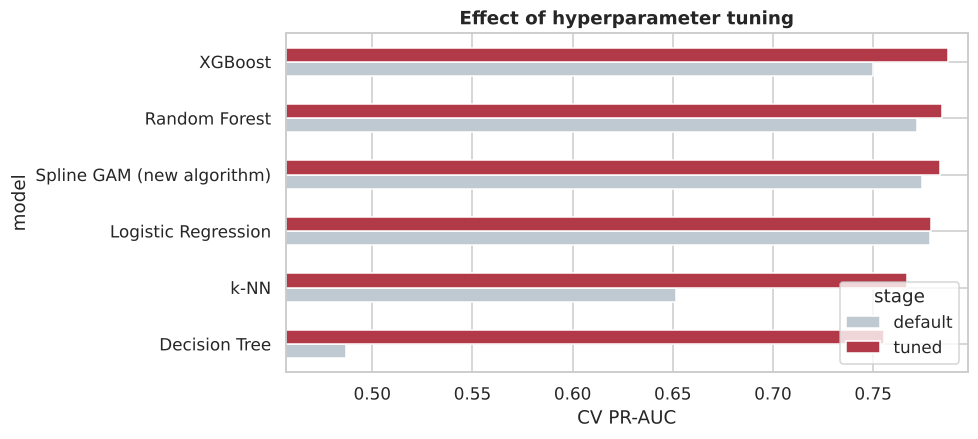

In [29]:
for name, m in tuned.items():
    p, s = cv_oof(m); oof_store[name] = p
    cv_rows.append({"model": name, "stage": "tuned", "CV PR-AUC": s.mean(), "CV PR-AUC sd": s.std(), "F1 @0.5": f1_score(y_oof, p >= .5)})
cv_tbl = pd.DataFrame(cv_rows)
display(cv_tbl.round(4))

dvt = cv_tbl[cv_tbl["stage"].isin(["default", "tuned"])].pivot(index="model", columns="stage", values="CV PR-AUC")
dvt["gain"] = dvt["tuned"] - dvt["default"]
display(dvt.sort_values("tuned", ascending=False).round(4))
ax = dvt.sort_values("tuned")[["default", "tuned"]].plot.barh(figsize=(8, 4), color=["#bfc9d1", "#b23a48"])
ax.set_xlim(dvt[["default", "tuned"]].values.min() - .03, dvt[["default", "tuned"]].values.max() + .01)
ax.set_xlabel("CV PR-AUC"); ax.set_title("Effect of hyperparameter tuning"); savefig("default_vs_tuned"); plt.show()

Each model's decision threshold maximises **F1 on its pooled out-of-fold CV predictions**. The test set is never used for this.
The **proposed model is the spline GAM**, chosen for the reasons in §8. The standard models answer one question: *does choosing an interpretable model cost accuracy here?*

In [30]:
SELECTED = "Spline GAM (new algorithm)"
cands = list(tuned)
thresholds = {n: best_threshold(y_oof, oof_store[n]) for n in cands}
thresholds["Persistence (next = now)"] = 0.5
thresholds["Seasonal naive (last year)"] = 0.5
cv_rank = cv_tbl[cv_tbl["stage"] == "tuned"].set_index("model")["CV PR-AUC"].sort_values(ascending=False)
print(cv_rank.round(4).to_string())
print(f"\nSpline GAM rank by CV PR-AUC: {list(cv_rank.index).index(SELECTED) + 1} of {len(cv_rank)} | gap to best standard model: "
      f"{cv_rank[SELECTED] - cv_rank.drop(SELECTED).max():+.4f} | decision threshold = {thresholds[SELECTED]:.2f}")

model
XGBoost                       0.7872
Random Forest                 0.7845
Spline GAM (new algorithm)    0.7836
Logistic Regression           0.7789
k-NN                          0.7671
Decision Tree                 0.7554

Spline GAM rank by CV PR-AUC: 3 of 6 | gap to best standard model: -0.0036 | decision threshold = 0.37


## 12. Final evaluation on the untouched test set (Jan 2024 – May 2026)
All tuned models are refit on the full development set (2007–2023) and scored **once** on the test period.

In [31]:
final_models = {n: clone(tuned[n]).fit(X_dev, y_dev) for n in cands}
final_models["Persistence (next = now)"] = PersistenceBaseline().fit(X_dev, y_dev)
test_pred = {n: m.predict_proba(X_test)[:, 1] for n, m in final_models.items()}
test_pred["Seasonal naive (last year)"] = (X_test["rel_same_week_last_year"].values > 0).astype(float)

res = pd.DataFrame({n: metrics(y_test, p, thresholds[n]) for n, p in test_pred.items()}).T
res["threshold"] = [thresholds[n] for n in res.index]
res = res.sort_values("PR-AUC", ascending=False)
display(res.round(3).style.highlight_max(subset=["ROC-AUC", "PR-AUC", "F1", "Bal. acc."], color="#f6d5d9").highlight_min(subset=["Brier"], color="#f6d5d9"))
res.round(4).to_csv(ROOT / "reports" / "test_results.csv")

,ROC-AUC,PR-AUC,F1,Precision,Recall,Bal. acc.,Brier,threshold
Random Forest,0.883000,0.806000,0.730000,0.676000,0.793000,0.797000,0.131000,0.360000
k-NN,0.881000,0.805000,0.730000,0.631000,0.864000,0.799000,0.135000,0.290000
XGBoost,0.883000,0.805000,0.735000,0.662000,0.826000,0.802000,0.133000,0.410000
Spline GAM (new algorithm),0.881000,0.800000,0.724000,0.685000,0.767000,0.791000,0.133000,0.370000
Logistic Regression,0.875000,0.785000,0.720000,0.673000,0.774000,0.788000,0.137000,0.360000
Decision Tree,0.862000,0.771000,0.704000,0.632000,0.793000,0.775000,0.189000,0.680000
Persistence (next = now),0.772000,0.592000,0.701000,0.695000,0.706000,0.772000,0.208000,0.500000
Seasonal naive (last year),0.585000,0.394000,0.472000,0.442000,0.506000,0.585000,0.390000,0.500000


In [32]:
# Block bootstrap over weeks (all 26 districts of a week resampled together) for 95% confidence intervals
rng = np.random.default_rng(SEED)
weeks = test["date"].values; uw = np.unique(weeks); widx = {w: np.where(weeks == w)[0] for w in uw}
boot = {n: [] for n in cands + ["Persistence (next = now)"]}
for _ in range(500):
    ii = np.concatenate([widx[w] for w in rng.choice(uw, len(uw), replace=True)])
    for n in boot:
        boot[n].append((average_precision_score(y_test[ii], test_pred[n][ii]), f1_score(y_test[ii], test_pred[n][ii] >= thresholds[n])))
ci = pd.DataFrame({n: {"PR-AUC 95% CI": f"{np.percentile([b[0] for b in v], 2.5):.3f} – {np.percentile([b[0] for b in v], 97.5):.3f}",
                       "F1 95% CI": f"{np.percentile([b[1] for b in v], 2.5):.3f} – {np.percentile([b[1] for b in v], 97.5):.3f}"} for n, v in boot.items()}).T
sel_boot = np.array(boot[SELECTED]); per_boot = np.array(boot["Persistence (next = now)"])
print(f"P(GAM F1 > persistence F1) over bootstrap = {(sel_boot[:,1] > per_boot[:,1]).mean():.3f}")
best_std = res.drop(index=[SELECTED, "Persistence (next = now)", "Seasonal naive (last year)"])["PR-AUC"].idxmax()
std_boot = np.array(boot[best_std])
print(f"P(GAM PR-AUC > {best_std} PR-AUC) over bootstrap = {(sel_boot[:,0] > std_boot[:,0]).mean():.3f}")
display(ci)

P(GAM F1 > persistence F1) over bootstrap = 0.994
P(GAM PR-AUC > Random Forest PR-AUC) over bootstrap = 0.040


,PR-AUC 95% CI,F1 95% CI
Spline GAM (new algorithm),0.765 – 0.833,0.691 – 0.753
Logistic Regression,0.748 – 0.821,0.688 – 0.749
Decision Tree,0.733 – 0.808,0.671 – 0.737
k-NN,0.768 – 0.839,0.700 – 0.757
Random Forest,0.771 – 0.840,0.698 – 0.759
XGBoost,0.770 – 0.837,0.704 – 0.764
Persistence (next = now),0.547 – 0.635,0.667 – 0.734


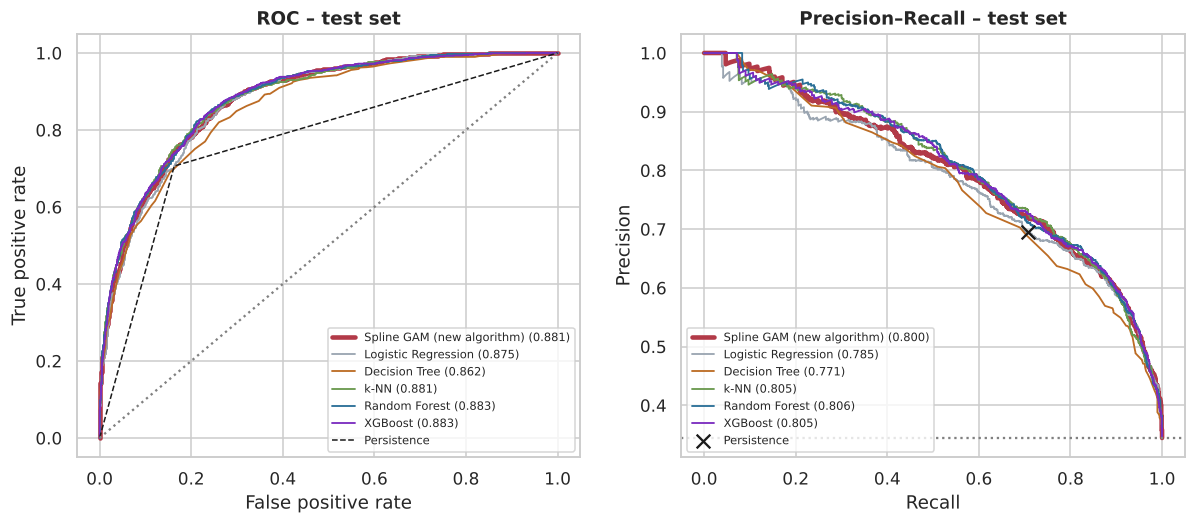

In [33]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
pal = dict(zip(cands, ["#b23a48", "#9aa5b1", "#bc6c25", "#6a994e", "#2a6f97", "#7b2cbf"]))
for n in cands:
    fpr, tpr, _ = roc_curve(y_test, test_pred[n]); pr, rc, _ = precision_recall_curve(y_test, test_pred[n])
    lw = 3 if n == SELECTED else 1.2
    axes[0].plot(fpr, tpr, lw=lw, color=pal[n], label=f"{n} ({roc_auc_score(y_test, test_pred[n]):.3f})")
    axes[1].plot(rc, pr, lw=lw, color=pal[n], label=f"{n} ({average_precision_score(y_test, test_pred[n]):.3f})")
pp = test_pred["Persistence (next = now)"]
axes[0].plot(*roc_curve(y_test, pp)[:2], "k--", lw=1, label="Persistence"); axes[1].scatter(recall_score(y_test, pp), precision_score(y_test, pp), c="k", marker="x", s=80, label="Persistence", zorder=5)
axes[0].plot([0, 1], [0, 1], ":", c="grey"); axes[0].set(xlabel="False positive rate", ylabel="True positive rate", title="ROC – test set")
axes[1].axhline(y_test.mean(), ls=":", c="grey"); axes[1].set(xlabel="Recall", ylabel="Precision", title="Precision–Recall – test set")
for a in axes: a.legend(fontsize=7.5, loc="lower right" if a is axes[0] else "lower left")
savefig("test_roc_pr"); plt.show()

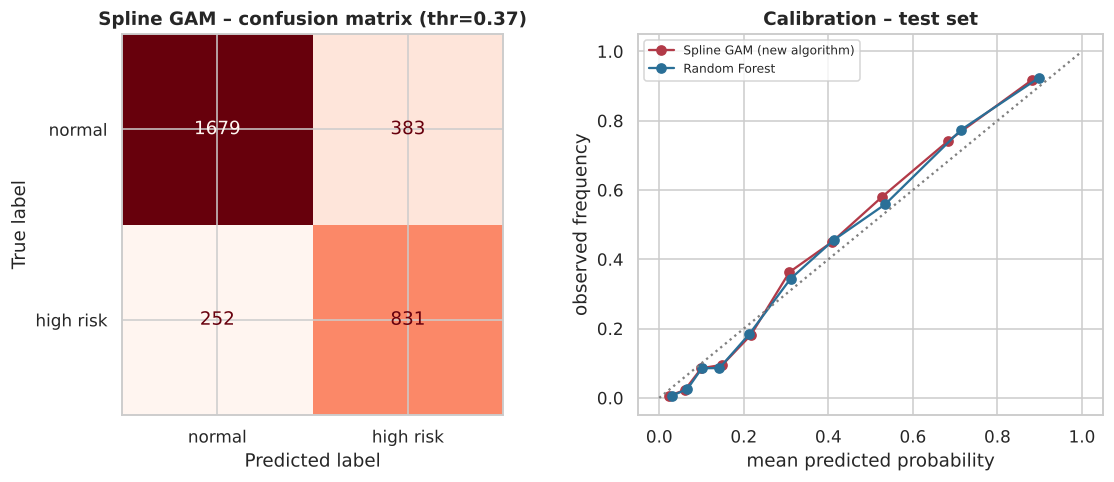

TN, FP, FN, TP = [1679  383  252  831]


In [34]:
best_model = final_models[SELECTED]; p_best = test_pred[SELECTED]; thr_best = thresholds[SELECTED]
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
ConfusionMatrixDisplay(confusion_matrix(y_test, p_best >= thr_best), display_labels=["normal", "high risk"]).plot(ax=axes[0], cmap="Reds", colorbar=False)
axes[0].set_title(f"Spline GAM – confusion matrix (thr={thr_best:.2f})")
for n in [SELECTED, best_std]:
    fp, mp = calibration_curve(y_test, test_pred[n], n_bins=10, strategy="quantile")
    axes[1].plot(mp, fp, "o-", label=n, color=pal[n])
axes[1].plot([0, 1], [0, 1], ":", c="grey"); axes[1].set(xlabel="mean predicted probability", ylabel="observed frequency", title="Calibration – test set"); axes[1].legend(fontsize=8)
savefig("test_confusion_calibration"); plt.show()
cm = confusion_matrix(y_test, p_best >= thr_best); print("TN, FP, FN, TP =", cm.ravel())

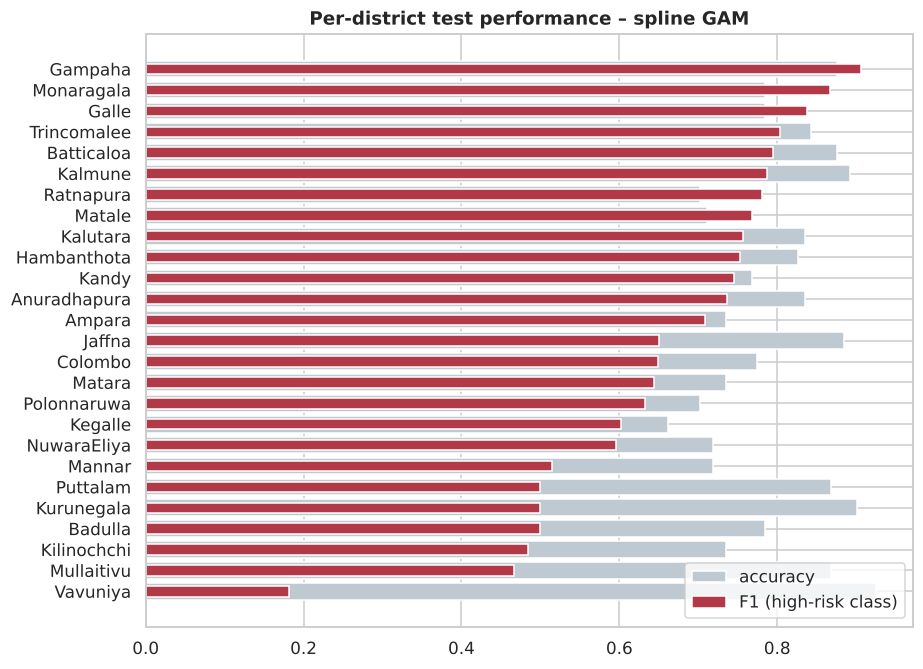

district,Vavuniya,Mullaitivu,Kilinochchi,Badulla,Kurunegala,Puttalam,Mannar,NuwaraEliya,Kegalle,Polonnaruwa,...,Hambanthota,Kalutara,Matale,Ratnapura,Kalmune,Batticaloa,Trincomalee,Galle,Monaragala,Gampaha
positive rate,0.02,0.13,0.26,0.17,0.1,0.10,0.27,0.34,0.38,0.39,...,0.36,0.31,0.57,0.69,0.23,0.29,0.36,0.63,0.81,0.65
F1,0.18,0.47,0.48,0.50,0.5,0.50,0.51,0.60,0.60,0.63,...,0.75,0.76,0.77,0.78,0.79,0.79,0.80,0.84,0.87,0.91
Recall,0.50,0.44,0.48,0.65,0.5,0.67,0.55,0.61,0.67,0.66,...,0.74,0.82,0.84,0.76,0.86,0.83,0.89,0.88,0.87,0.91
Accuracy,0.93,0.87,0.74,0.79,0.9,0.87,0.72,0.72,0.66,0.70,...,0.83,0.83,0.71,0.70,0.89,0.88,0.84,0.79,0.79,0.88


In [35]:
test_eval = test.assign(p=p_best, pred=(p_best >= thr_best).astype(int))
per_d = test_eval.groupby("district").apply(lambda g: pd.Series({
    "positive rate": g["high_risk"].mean(),
    "F1": f1_score(g["high_risk"], g["pred"], zero_division=0),
    "Recall": recall_score(g["high_risk"], g["pred"], zero_division=0),
    "Accuracy": (g["high_risk"] == g["pred"]).mean()})).sort_values("F1")
fig, ax = plt.subplots(figsize=(9, 7))
ax.barh(per_d.index, per_d["Accuracy"], color="#bfc9d1", label="accuracy")
ax.barh(per_d.index, per_d["F1"], color="#b23a48", height=.5, label="F1 (high-risk class)")
ax.set_title("Per-district test performance – spline GAM"); ax.legend(loc="lower right")
savefig("test_per_district"); plt.show()
display(per_d.round(2).T)

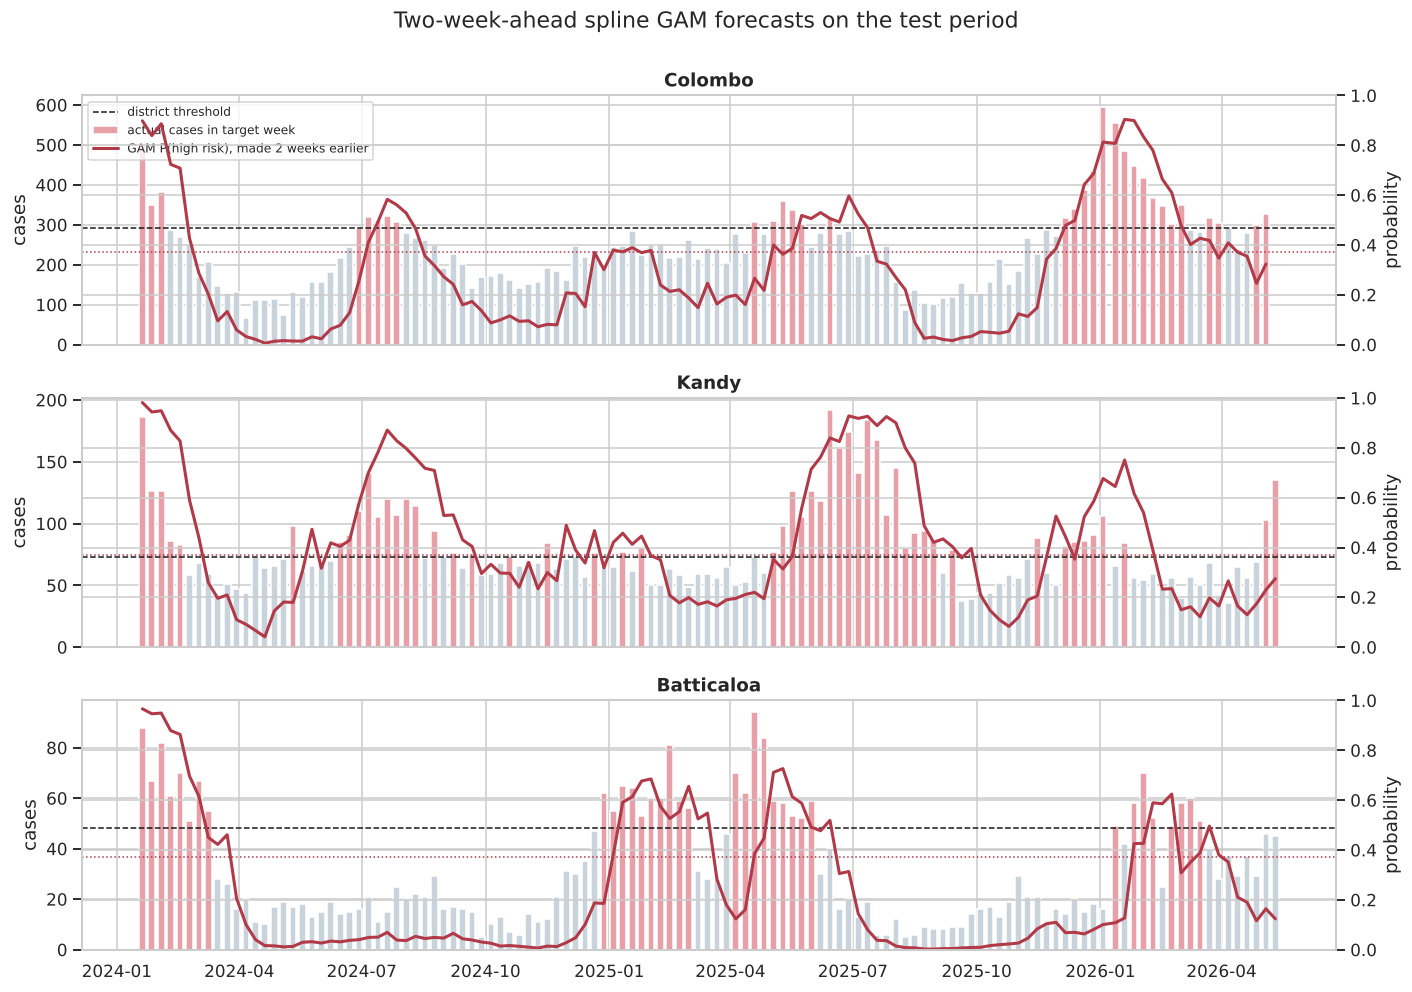

In [36]:
fig, axes = plt.subplots(3, 1, figsize=(13, 9), sharex=True)
for ax, d in zip(axes, ["Colombo", "Kandy", "Batticaloa"]):
    g = test_eval[test_eval["district"] == d]
    ax.bar(g["target_date"], g["target_cases"], width=5, color=np.where(g["high_risk"] == 1, "#e8a0a8", "#c9d3dc"), label="actual cases in target week")
    ax.axhline(g["threshold"].iloc[0], c="k", ls="--", lw=1, label="district threshold")
    ax2 = ax.twinx(); ax2.plot(g["target_date"], g["p"], c="#b23a48", lw=2, label="GAM P(high risk), made 2 weeks earlier")
    ax2.axhline(thr_best, c="#b23a48", ls=":", lw=1); ax2.set_ylim(0, 1); ax2.set_ylabel("probability")
    ax.set_title(d); ax.set_ylabel("cases")
    if d == "Colombo":
        h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels(); ax.legend(h1 + h2, l1 + l2, fontsize=8, loc="upper left")
fig.suptitle("Two-week-ahead spline GAM forecasts on the test period", y=1.0); fig.tight_layout(); savefig("test_timelines"); plt.show()

### 12.1 What the results show

| Test set (Jan 2024 – May 2026) | ROC-AUC | PR-AUC | F1 | Precision | Recall | Bal. acc. |
|---|---|---|---|---|---|---|
| **Spline GAM (new algorithm)** | **0.881** | **0.800** | **0.724** | **0.685** | 0.767 | **0.791** |
| Random Forest (standard) | 0.883 | 0.806 | 0.730 | 0.676 | 0.793 | 0.797 |
| k-NN (standard) | 0.881 | 0.805 | 0.730 | 0.631 | 0.864 | 0.800 |
| XGBoost (standard) | 0.883 | 0.805 | 0.735 | 0.662 | 0.826 | 0.802 |
| Logistic regression (standard) | 0.875 | 0.785 | 0.720 | 0.673 | 0.774 | 0.788 |
| Decision tree (standard) | 0.862 | 0.771 | 0.704 | 0.632 | 0.793 | 0.775 |
| Persistence baseline | 0.772 | 0.592 | 0.700 | 0.695 | 0.706 | 0.772 |
| Seasonal naive | 0.585 | 0.394 | 0.472 | 0.442 | 0.506 | 0.585 |

1. **The spline GAM is a useful early-warning model.** Against the persistence rule ("next is like now"), PR-AUC rises from 0.59 to 0.80 and recall from 71% to 77%, at about the same precision. F1 is higher than persistence in 99% of bootstrap resamples.
2. **It is close to the black-box models.** In cross-validation its PR-AUC (0.784) is third of six, 0.004 behind XGBoost (0.787) and 0.001 behind Random Forest (0.785). On the test period it reaches 0.800, within 0.006 of the best model (Random Forest 0.806), with the same ROC-AUC as k-NN (0.881) and the **highest precision of all trained models** (0.685). Its PR-AUC confidence interval (0.765–0.833) overlaps strongly with Random Forest's (0.771–0.840). Random Forest is still ahead in 96% of bootstrap resamples, so a small gap remains, but it is about a fifth of a point on F1.
3. **It is clearly better than the other interpretable standard models:** logistic regression (0.785; a GAM is its curved generalisation) and the decision tree (0.771).
4. **Tuning helped modestly** (+0.009 CV PR-AUC). The penalty `lam` mattered most (importance 0.42), then the number of interactions (0.32). The search chose a strong penalty (lam ≈ 509), 16 quadratic splines per feature and one interaction (`rel_now × district_baseline`): a smooth, low-variance model with about 41 effective degrees of freedom.
5. **Errors.** On 3,145 test district-weeks, the GAM caught **831** high weeks and missed **252**, raised **383** false alarms, and correctly cleared **1,679** normal weeks. The CV-chosen threshold is 0.37.
6. **Hold-out point.** Colombo, week of 27 Apr 2026 (300 cases, threshold 291): P = 0.33, just *below* the 0.37 alert threshold, so the model predicted "normal". Two weeks later Colombo reported 308 cases, a HIGH week, so this single prediction was **wrong, by a narrow margin**. The case sat right at the threshold (300 vs 291 cases, then 308), the kind of borderline week where a two-week forecast is least certain. The threshold was not changed after seeing this, because that would tune the model on its own test point.

**Why the spline GAM is the proposed model.** It is a new algorithm (not in the lectures), its accuracy is within cross-validation noise of the best black boxes and close to them on the test period, and every prediction is an exact, auditable sum of smooth curves (§13). For a public-health alert, that transparency is worth a very small loss in ranking accuracy.

### 12.2 Could accuracy be higher? Other algorithms and GAM variants

To check whether another **new** algorithm (not in the lectures, not deep learning) would do better, other algorithms and several GAM refinements were scored with the **same expanding-window CV**.
Selection uses CV only. Test PR-AUC is listed for reference; choosing a model by test score would leak the test period into model selection.
The scripts are `scripts/other_algorithms.py` and `scripts/gam_cv_experiments.py`; they take about 15 minutes, so their saved results are loaded here.

In [37]:
other = pd.read_csv(ROOT / "reports" / "other_algorithms.csv").sort_values("cv_pr_auc", ascending=False)
print("Algorithms not covered in lectures (sorted by CV PR-AUC):")
print(other.round(4).to_string(index=False))
ablation = pd.read_csv(ROOT / "reports" / "gam_cv_ablation.csv")
print("\nSpline GAM refinements (CV PR-AUC):")
print(ablation.round(4).to_string(index=False))

Algorithms not covered in lectures (sorted by CV PR-AUC):
                                 algorithm  cv_pr_auc  test_pr_auc
                                   NGBoost     0.7848       0.7951
                Spline GAM (chosen, tuned)     0.7836       0.7996
                                   RuleFit     0.7827       0.7957
                               Extra Trees     0.7819       0.8054
                      Gaussian Naive Bayes     0.7563       0.7582
FIGS (fast interpretable greedy-tree sums)     0.7532       0.7789
                                       LDA     0.7291       0.7135
                                       QDA     0.6768       0.7108

Spline GAM refinements (CV PR-AUC):
                           variant  cv_pr_auc
                  tuned (selected)     0.7836
 no interactions (purely additive)     0.7819
      all 3 candidate interactions     0.7827
monotone curves for level features     0.7821
               lam x 10 (smoother)     0.7805
               lam / 10 (w

**Reading.** By the selection criterion (CV), the spline GAM is **2nd of 8** non-lecture algorithms, 0.001 behind NGBoost. NGBoost is a black-box gradient-boosting variant, and gradient boosting is a lecture topic. Extra Trees (a Random Forest/bagging variant) scores higher on test but lower in CV and is also a black box. RuleFit is interpretable but slightly lower in CV and about 6× slower, and its rules come from tree ensembles plus Lasso (both lecture topics). FIGS, Naive Bayes, LDA and QDA are clearly weaker.
None of the GAM refinements improved CV PR-AUC (range 0.781–0.784, all within noise): removing or adding interactions, monotone constraints on the level features, a 10× stronger or weaker penalty, and weighting recent years more. **The tuned GAM is kept.**

## 13. Explainability
The spline GAM is interpretable by design, so explanations come from **three independent angles**:
1. **The GAM's own glass-box explanations:** global term importance, the learned spline curves with 95% confidence bands (these *are* the model's exact partial-dependence curves), the interaction surface, and exact local contributions.
2. **SHAP:** model-agnostic Shapley values (permutation explainer).
3. **LIME:** local surrogate models.

### 13.1 Glass-box explanations from the spline GAM

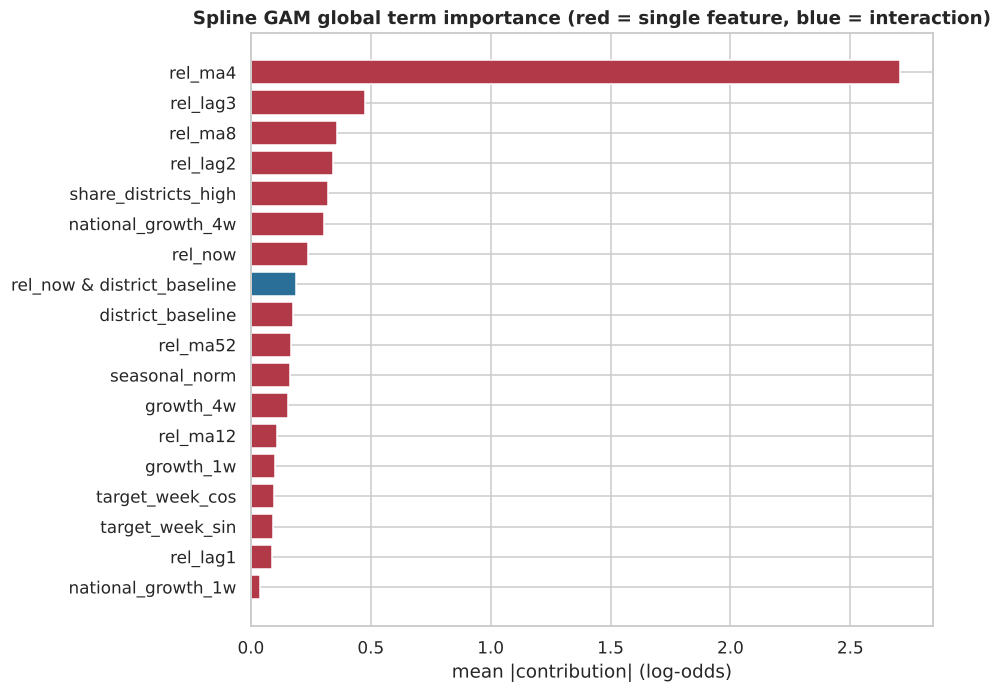

20 terms: 19 single-feature spline curves + 1 tensor-product interactions
effective degrees of freedom of the whole model: 41.1


,importance
rel_ma4,2.709
rel_lag3,0.474
rel_ma8,0.360
rel_lag2,0.341
share_districts_high,0.322
national_growth_4w,0.304
rel_now,0.238
rel_now & district_baseline,0.190
district_baseline,0.174
rel_ma52,0.169


In [38]:
term_names = list(best_model.term_names_)
dev_contrib = best_model.term_contributions(X_dev)
term_imp = dev_contrib.abs().mean().sort_values(ascending=False)   # mean |contribution| over the development set
fig, ax = plt.subplots(figsize=(8, 7))
top = term_imp.head(18)[::-1]
ax.barh(top.index, top.values, color=["#2a6f97" if " & " in t else "#b23a48" for t in top.index])
ax.set_xlabel("mean |contribution| (log-odds)"); ax.set_title("Spline GAM global term importance (red = single feature, blue = interaction)")
savefig("gam_importance"); plt.show()
print(f"{len(term_names)} terms: {sum(' & ' not in t for t in term_names)} single-feature spline curves + {sum(' & ' in t for t in term_names)} tensor-product interactions")
print(f"effective degrees of freedom of the whole model: {best_model.gam_.statistics_['edof']:.1f}")
display(term_imp.head(10).round(3).to_frame("importance"))

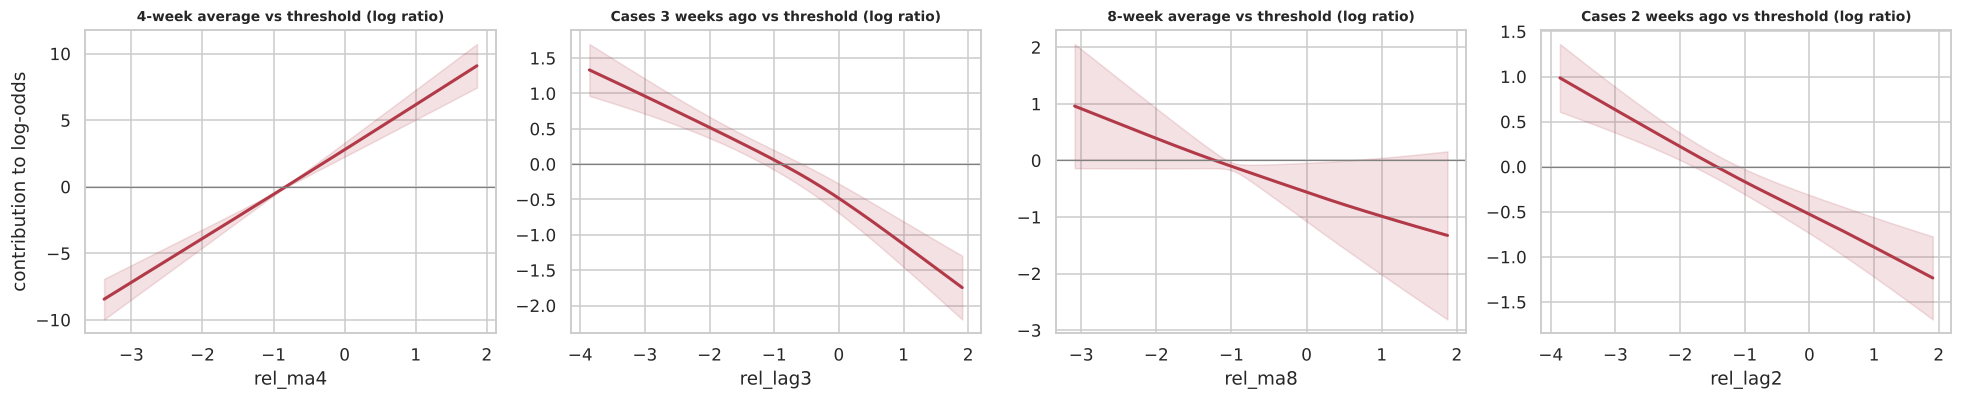

In [39]:
# Learned spline curves of the most important single features: the model's exact partial dependence, with 95% confidence bands
g = best_model.gam_
singles = [t for t in term_imp.index if " & " not in t][:4]
fig, axes = plt.subplots(1, 4, figsize=(18, 3.8))
for ax, t in zip(axes, singles):
    i = term_names.index(t)
    XX = g.generate_X_grid(term=i, n=200)
    pdep, ci = g.partial_dependence(term=i, X=XX, width=0.95)
    lo, hi = np.percentile(X_dev[t], [1, 99]); keep = (XX[:, i] >= lo) & (XX[:, i] <= hi)   # central 98% of the data
    ax.plot(XX[keep, i], pdep[keep], color="#b23a48", lw=2)
    ax.fill_between(XX[keep, i], ci[keep, 0], ci[keep, 1], color="#b23a48", alpha=.15)
    ax.axhline(0, c="grey", lw=.8); ax.set_title(FEATURE_DESCRIPTIONS.get(t, t), fontsize=9); ax.set_xlabel(t)
axes[0].set_ylabel("contribution to log-odds")
plt.tight_layout(); savefig("gam_shape_functions"); plt.show()

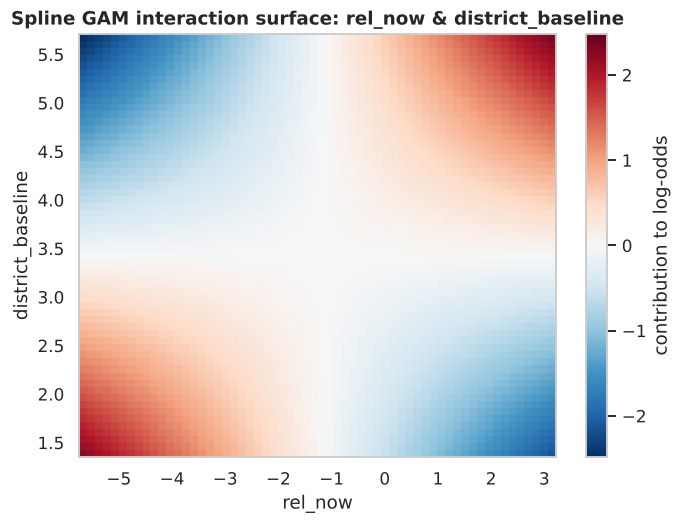

In [40]:
# The strongest interaction as a heat map of its tensor-product spline surface
pairs = [t for t in term_imp.index if " & " in t]
if pairs:
    t = pairs[0]; i = term_names.index(t); a, b = t.split(" & ")
    XX = g.generate_X_grid(term=i, meshgrid=True, n=60)
    Z = g.partial_dependence(term=i, X=XX, meshgrid=True)
    fig, ax = plt.subplots(figsize=(7, 5))
    lim = np.abs(Z).max()
    im = ax.pcolormesh(XX[0], XX[1], Z, cmap="RdBu_r", vmin=-lim, vmax=lim, shading="auto")
    ax.set_xlabel(a); ax.set_ylabel(b); ax.set_title(f"Spline GAM interaction surface: {t}")
    plt.colorbar(im, label="contribution to log-odds"); savefig("gam_interaction"); plt.show()
else:
    print("The tuned model is purely additive (no interaction terms).")

intercept -2.394 + sum of contributions +1.697 = -0.697 log-odds -> P = 0.333 (model.predict_proba = 0.333)


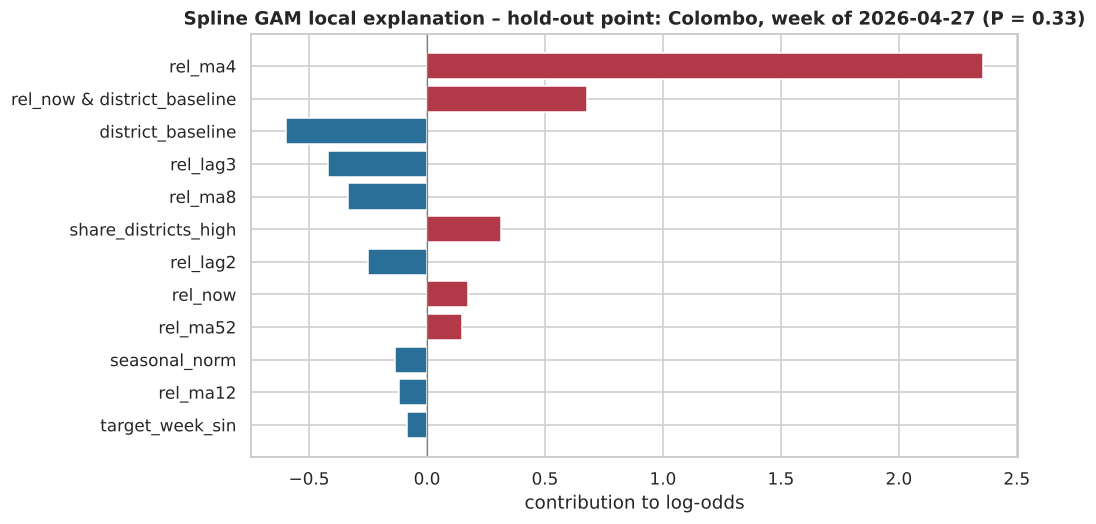

In [41]:
# Exact local explanation for the hold-out point: intercept + term contributions = model log-odds
X_ho = holdout[FEATURES]
contrib = best_model.term_contributions(X_ho).iloc[0]
intercept = best_model.intercept_
logit = intercept + contrib.sum(); p_check = 1 / (1 + np.exp(-logit))
print(f"intercept {intercept:+.3f} + sum of contributions {contrib.sum():+.3f} = {logit:+.3f} log-odds -> P = {p_check:.3f} "
      f"(model.predict_proba = {best_model.predict_proba(X_ho)[0, 1]:.3f})")
top_c = contrib.reindex(contrib.abs().sort_values(ascending=False).index).head(12)[::-1]
fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(top_c.index, top_c.values, color=["#b23a48" if v > 0 else "#2a6f97" for v in top_c.values])
ax.axvline(0, c="grey", lw=.8); ax.set_xlabel("contribution to log-odds")
ax.set_title(f"Spline GAM local explanation – hold-out point: {holdout['district'].iloc[0]}, week of {holdout['date'].iloc[0].date()} (P = {p_check:.2f})")
savefig("gam_local_holdout"); plt.show()

### 13.2 SHAP (model-agnostic Shapley values)

PermutationExplainer explainer:   3%|▎         | 13/400 [00:00<?, ?it/s]

PermutationExplainer explainer:   4%|▍         | 15/400 [00:10<02:25,  2.64it/s]

PermutationExplainer explainer:   4%|▍         | 16/400 [00:11<03:23,  1.89it/s]

PermutationExplainer explainer:   4%|▍         | 17/400 [00:12<03:56,  1.62it/s]

PermutationExplainer explainer:   4%|▍         | 18/400 [00:13<04:07,  1.54it/s]

...

PermutationExplainer explainer: 100%|█████████▉| 398/400 [04:22<00:01,  1.54it/s]

PermutationExplainer explainer: 100%|█████████▉| 399/400 [04:22<00:00,  1.56it/s]

PermutationExplainer explainer: 100%|██████████| 400/400 [04:23<00:00,  1.57it/s]

PermutationExplainer explainer: 401it [04:24,  1.58it/s]                         

PermutationExplainer explainer: 401it [04:24,  1.47it/s]

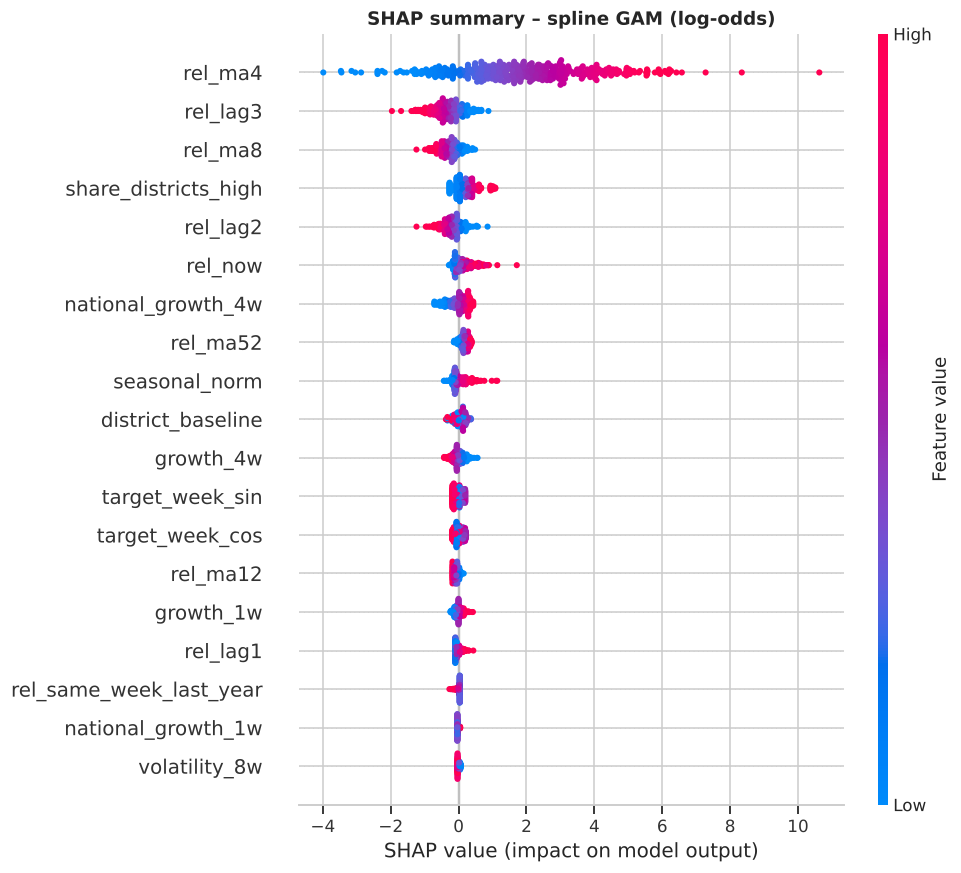

In [42]:
bg = shap.sample(X_dev, 100, random_state=SEED)
def f_logit(X):
    p = np.clip(best_model.predict_proba(pd.DataFrame(X, columns=FEATURES))[:, 1], 1e-6, 1 - 1e-6)
    return np.log(p / (1 - p))
explainer = shap.PermutationExplainer(f_logit, bg)
X_shap = X_test.sample(400, random_state=SEED)
sv = explainer(X_shap)
shap.plots.beeswarm(sv, max_display=19, show=False); plt.title("SHAP summary – spline GAM (log-odds)"); savefig("shap_beeswarm"); plt.show()

Spearman rank correlation, SHAP vs GAM feature importance: 0.972


,SHAP mean |value|,GAM importance
rel_ma4,2.307,2.709
rel_lag3,0.431,0.474
rel_ma8,0.303,0.360
share_districts_high,0.283,0.322
rel_lag2,0.268,0.341
rel_now,0.199,0.333
national_growth_4w,0.187,0.304
rel_ma52,0.182,0.169
seasonal_norm,0.157,0.162
district_baseline,0.126,0.269


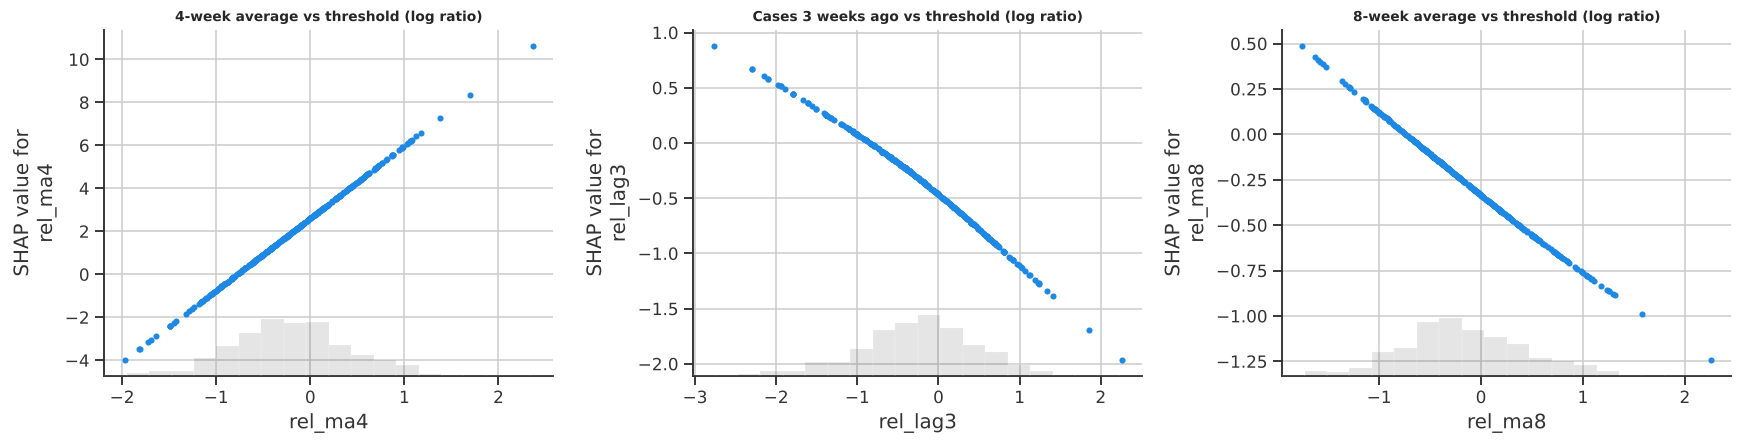

In [43]:
shap_imp = pd.Series(np.abs(sv.values).mean(0), index=FEATURES).sort_values(ascending=False)
# the GAM's own importance per *feature* (single term + half of each interaction it belongs to)
gam_feat = pd.Series(0.0, index=FEATURES)
for t, v in term_imp.items():
    parts = t.split(" & ")
    for p in parts:
        gam_feat[p] += v / len(parts)
cmp_imp = pd.DataFrame({"SHAP mean |value|": shap_imp, "GAM importance": gam_feat}).sort_values("SHAP mean |value|", ascending=False)
print("Spearman rank correlation, SHAP vs GAM feature importance:", round(cmp_imp.corr(method="spearman").iloc[0, 1], 3))
display(cmp_imp.round(3).head(10))
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
for ax, f in zip(axes, shap_imp.index[:3]):
    shap.plots.scatter(sv[:, f], ax=ax, show=False); ax.set_title(FEATURE_DESCRIPTIONS[f], fontsize=9)
plt.tight_layout(); savefig("shap_dependence"); plt.show()

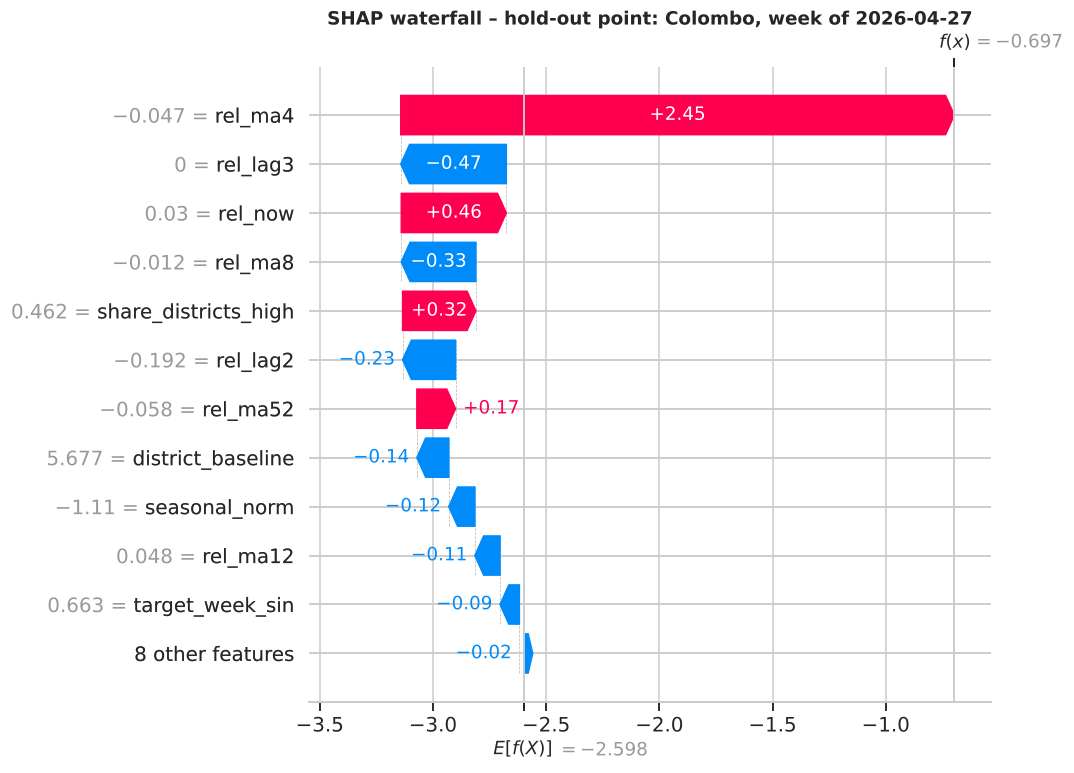

In [44]:
sv_ho = explainer(X_ho)
shap.plots.waterfall(sv_ho[0], max_display=12, show=False)
plt.title(f"SHAP waterfall – hold-out point: {holdout['district'].iloc[0]}, week of {holdout['date'].iloc[0].date()}")
savefig("shap_waterfall_holdout"); plt.show()

### 13.3 LIME (local surrogate explanations)
LIME perturbs one instance, queries the model, and fits a weighted linear model around that point. It's applied to
(a) the hold-out point, (b) a correctly predicted outbreak onset, and (c) a missed outbreak, with a stability check across random seeds.

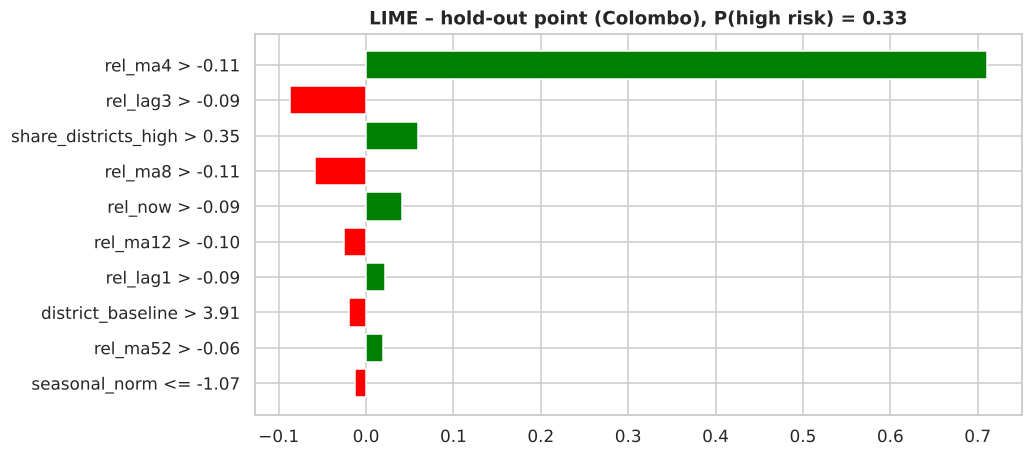

,condition,LIME weight
0,rel_ma4 > -0.11,0.711
1,rel_lag3 > -0.09,-0.088
2,share_districts_high > 0.35,0.059
3,rel_ma8 > -0.11,-0.058
4,rel_now > -0.09,0.041
5,rel_ma12 > -0.10,-0.026
6,rel_lag1 > -0.09,0.021
7,district_baseline > 3.91,-0.020
8,rel_ma52 > -0.06,0.019
9,seasonal_norm <= -1.07,-0.013


In [45]:
predict_fn = lambda X: best_model.predict_proba(pd.DataFrame(X, columns=FEATURES))
lime_exp = lime.lime_tabular.LimeTabularExplainer(X_dev.values, feature_names=FEATURES, class_names=["normal", "high risk"],
                                                  mode="classification", discretize_continuous=True, random_state=SEED)
e_ho = lime_exp.explain_instance(X_ho.values[0], predict_fn, num_features=10, num_samples=5000)
fig = e_ho.as_pyplot_figure(label=1); fig.set_size_inches(9, 4.5)
plt.title(f"LIME – hold-out point ({holdout['district'].iloc[0]}), P(high risk) = {predict_fn(X_ho.values)[0,1]:.2f}")
savefig("lime_holdout"); plt.show()
display(pd.DataFrame(e_ho.as_list(label=1), columns=["condition", "LIME weight"]).round(3))

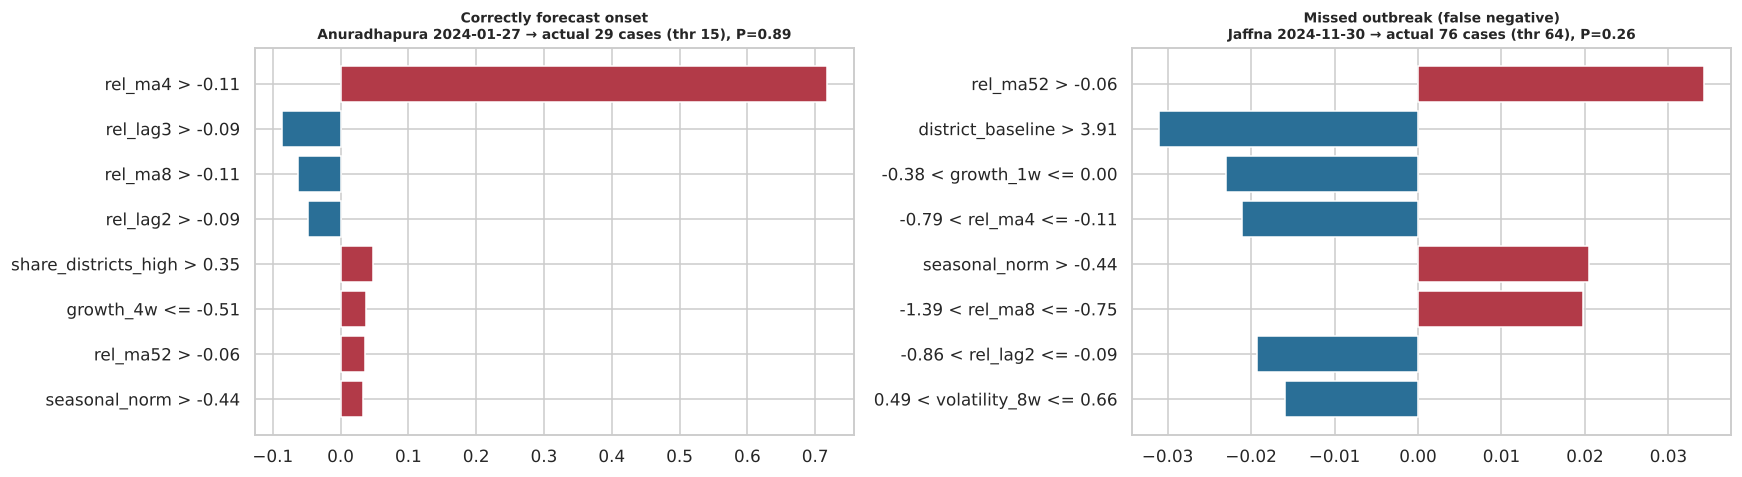

In [46]:
te = test_eval.assign(prev=(test_eval["rel_now"] > 0).astype(int))
onset_tp = te[(te["prev"] == 0) & (te["high_risk"] == 1) & (te["pred"] == 1)]
missed = te[(te["high_risk"] == 1) & (te["pred"] == 0)]
cases_lime = {"Correctly forecast onset": onset_tp.sort_values("p", ascending=False).iloc[0],
              "Missed outbreak (false negative)": missed.sort_values("p").iloc[len(missed) // 2]}
fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))
for ax, (lab, row) in zip(axes, cases_lime.items()):
    e = lime_exp.explain_instance(row[FEATURES].values.astype(float), predict_fn, num_features=8, num_samples=5000)
    items = e.as_list(label=1)[::-1]
    ax.barh([i[0] for i in items], [i[1] for i in items], color=["#b23a48" if i[1] > 0 else "#2a6f97" for i in items])
    ax.set_title(f"{lab}\n{row['district']} {row['date'].date()} → actual {int(row['target_cases'])} cases (thr {row['threshold']:.0f}), P={row['p']:.2f}", fontsize=9)
plt.tight_layout(); savefig("lime_cases"); plt.show()

In [47]:
tops = []
for s in range(5):
    le = lime.lime_tabular.LimeTabularExplainer(X_dev.values, feature_names=FEATURES, class_names=["normal", "high risk"],
                                                mode="classification", discretize_continuous=True, random_state=s)
    ex = le.explain_instance(X_ho.values[0], predict_fn, num_features=5, num_samples=5000)
    tops.append(sorted([FEATURES[i] for i, _ in ex.as_map()[1]]))
print("Top-5 LIME features per seed:"); [print(" ", t) for t in tops]
print("Features in all 5 runs:", sorted(set.intersection(*map(set, tops))))

Top-5 LIME features per seed:
  ['rel_lag3', 'rel_ma4', 'rel_ma8', 'rel_now', 'share_districts_high']
  ['rel_lag3', 'rel_ma4', 'rel_ma8', 'rel_now', 'share_districts_high']
  ['rel_lag3', 'rel_ma4', 'rel_ma52', 'rel_ma8', 'share_districts_high']
  ['rel_lag3', 'rel_ma4', 'rel_ma8', 'rel_now', 'share_districts_high']
  ['rel_lag3', 'rel_ma4', 'rel_ma8', 'rel_now', 'share_districts_high']
Features in all 5 runs: ['rel_lag3', 'rel_ma4', 'rel_ma8', 'share_districts_high']


In [48]:
# Agreement of the three explanation methods on the hold-out point (per feature; interactions split equally)
gam_local = pd.Series(0.0, index=FEATURES)
for t, v in contrib.items():
    parts = t.split(" & ")
    for p in parts:
        gam_local[p] += v / len(parts)
lime_w = pd.Series({FEATURES[i]: w for i, w in e_ho.as_map()[1]})
agree = pd.DataFrame({"GAM exact": gam_local, "SHAP": pd.Series(sv_ho.values[0], index=FEATURES), "LIME": lime_w}).dropna()
agree = agree.reindex(agree["GAM exact"].abs().sort_values(ascending=False).index)
agree["GAM–SHAP same sign"] = np.sign(agree["GAM exact"]) == np.sign(agree["SHAP"])
agree["GAM–LIME same sign"] = np.sign(agree["GAM exact"]) == np.sign(agree["LIME"])
display(agree.round(3))
print(f"Sign agreement on LIME's top-10 features: GAM–SHAP {agree['GAM–SHAP same sign'].mean():.0%}, GAM–LIME {agree['GAM–LIME same sign'].mean():.0%}")

,GAM exact,SHAP,LIME,GAM–SHAP same sign,GAM–LIME same sign
rel_ma4,2.358,2.445,0.711,True,True
rel_now,0.511,0.464,0.041,True,True
rel_lag3,-0.419,-0.466,-0.088,True,True
rel_ma8,-0.336,-0.330,-0.058,True,True
share_districts_high,0.312,0.324,0.059,True,True
district_baseline,-0.260,-0.141,-0.020,True,True
rel_ma52,0.148,0.171,0.019,True,True
seasonal_norm,-0.136,-0.115,-0.013,True,True
rel_ma12,-0.121,-0.111,-0.026,True,True
rel_lag1,-0.019,-0.023,0.021,True,False


Sign agreement on LIME's top-10 features: GAM–SHAP 100%, GAM–LIME 90%


### 13.4 Interpreting the model (GAM curves, SHAP, LIME)

**What the model has learned.** The tuned GAM has **20 terms**: 19 single-feature spline curves plus 1 tensor-product interaction, about 41 effective degrees of freedom in total.
1. **The 4-week average relative to the district threshold dominates** (importance 2.71, far above any other term). Its curve rises almost linearly on the log-odds scale: from about −8 when cases are ~30× below threshold, through 0 at about 40% of the threshold, to about +9 well above it.
2. **Momentum, read from the lag curves.** Holding the 4-week average fixed, the curves for cases **3 weeks ago** (0.47), **2 weeks ago** (0.34) and the **8-week average** (0.36) slope *downwards*. If the 4-week average is mostly made of older weeks, the district is past its peak and risk falls; if the same average comes from recent weeks, the outbreak is growing. The GAM has learned a smooth, readable version of the epidemic trend.
3. **The national wave matters.** `share_districts_high` (0.32) and `national_growth_4w` (0.30) raise every district's risk when dengue is rising across the country.
4. **The one interaction: this week's level × district burden** (0.19). In **high-burden districts** (Colombo, Gampaha; top of the surface in §13.1) a week above threshold adds up to +2 log-odds, because high counts persist there. In **small districts** the same signal points the other way: one high week is often noise that falls back.
5. **Season** (`seasonal_norm`, the target-week sine/cosine) adds the post-monsoon peaks.

**The three explanation methods agree.** Feature rankings from the GAM's own importance and from SHAP correlate at **Spearman 0.97**. On the hold-out point, SHAP has the same sign as the GAM's exact contribution on **all 10** of LIME's top features, and LIME agrees on 9 of 10. LIME's top-5 set always contains the same four core features (`rel_ma4`, `rel_lag3`, `rel_ma8`, `share_districts_high`) across five random seeds.

**Local explanations.**
* **Hold-out point (Colombo, 27 Apr 2026).** Intercept −2.39 log-odds (an average week); then the 4-week average +2.36, the Colombo level × burden interaction +0.68, the national share +0.31 and this week's level +0.17; against these, Colombo's own baseline −0.60, the older weeks (3 weeks ago −0.42, the 8-week average −0.34, 2 weeks ago −0.25), and season −0.14. The total is −0.70 log-odds, so P = 0.33, just below the 0.37 alert line. Colombo then reported 308 cases (threshold 291), so this borderline forecast was wrong. The explanation shows why: the model read the older weeks as a sign the wave was flattening. Because the GAM is additive, these numbers are **exactly** the model's computation, not an approximation.
* **Correctly forecast onset (Anuradhapura, Jan 2024, P = 0.89):** the 4-week average had climbed near the threshold during a national wave. Two weeks later it had 29 cases against a threshold of 15.
* **Missed outbreak (Jaffna, Nov 2024, P = 0.26):** recent weeks were below threshold with a flat trend, and the outbreak (76 cases, threshold 64) arrived with the north-east monsoon faster than the counts showed. Sudden rises without an early signal in the counts are the model's main blind spot.

**Alignment with domain knowledge.** Transmission persists over weeks (mosquito and virus cycles), so recent level dominates. Rising versus falling waves matter, and the lag curves encode exactly that. Epidemics are nationwide, driven by circulating serotypes. Risk peaks after the south-west (May–September) and north-east (December–February) monsoons. And persistence is stronger in dense urban districts with year-round transmission. The model reasons the way a surveillance epidemiologist would, and as a glass box every curve can be checked and challenged.

## 14. Save the model and run inference on the held-out data point

In [49]:
bundle = {
    "model": best_model,
    "model_name": "Spline GAM (generalized additive model)",
    "features": FEATURES,
    "feature_descriptions": FEATURE_DESCRIPTIONS,
    "decision_threshold": thr_best,
    "reference": ref,
    "horizon_weeks": HORIZON,
    "reference_years": REFERENCE_YEARS,
    "trained_on": f"{dev['date'].min().date()} to {dev['date'].max().date()} ({len(dev)} district-weeks)",
    "test_metrics": res.loc[SELECTED].drop("threshold").round(4).to_dict(),
    "best_params": best_params[SELECTED],
}
joblib.dump(bundle, MODELS / "dengue_model.pkl")
meta = {k: v for k, v in bundle.items() if k not in ("model", "reference")}
json.dump(meta, open(MODELS / "model_metadata.json", "w"), indent=2, default=str)
df.drop(columns=["woy", "rel"]).to_csv(ROOT / "data" / "processed" / "dengue_weekly_clean.csv", index=False)
print("Saved:", MODELS / "dengue_model.pkl", f"({(MODELS / 'dengue_model.pkl').stat().st_size / 1e6:.1f} MB)")

Saved: /home/claude/dengue-early-warning/models/dengue_model.pkl (1.0 MB)


In [50]:
# --- fresh load, exactly as the app does ---
loaded = joblib.load(MODELS / "dengue_model.pkl")
ho = pd.read_csv(ROOT / "data" / "holdout_sample.csv", parse_dates=["date", "target_date"])
p_ho = loaded["model"].predict_proba(ho[loaded["features"]])[:, 1][0]
r = ho.iloc[0]
print(f"District           : {r['district']}")
print(f"Report week        : {r['date'].date()}  (cases this week = {int(r['cases'])})")
print(f"Forecast for week  : {r['target_date'].date()}  (threshold = {r['threshold']:.0f} cases)")
print(f"P(high risk)       : {p_ho:.3f}  -> predicted {'HIGH RISK' if p_ho >= loaded['decision_threshold'] else 'normal'} (decision threshold {loaded['decision_threshold']:.2f})")
print(f"Actual outcome     : {int(r['target_cases'])} cases -> {'HIGH RISK' if r['high_risk'] == 1 else 'normal'}")

District           : Colombo
Report week        : 2026-04-27  (cases this week = 300)
Forecast for week  : 2026-05-11  (threshold = 291 cases)
P(high risk)       : 0.333  -> predicted normal (decision threshold 0.37)
Actual outcome     : 308 cases -> HIGH RISK


## 15. Conclusions

**Summary.** Using 20 years of official Sri Lankan dengue surveillance data, I built a two-week-ahead early-warning classifier for all 26 RDHS areas, using a **new algorithm: a spline Generalized Additive Model (GAM)**, fitted by penalised likelihood with pyGAM.
After a careful EDA, three kinds of data problem were found and handled (a missing week, a year of zeros for Monaragala, and 22 implausible or misaligned weekly values). Nineteen leakage-free, scale-free features were engineered.
The GAM was tuned with Optuna under expanding-window time-series cross-validation and compared with five standard models. On 2½ years of unseen data it reaches **ROC-AUC 0.88, PR-AUC 0.80, F1 0.72 and the highest precision of all trained models (0.68)**, far above the persistence baseline (PR-AUC 0.59) and within 0.006 PR-AUC of the best black box. Every prediction comes with an **exact explanation** as a sum of smooth curves, cross-checked with SHAP and LIME.

**Guideline → where it's met**
* §1 Problem, data source, features, size, preprocessing, ethics: notebook §1–2, §4–6
* §2 New algorithm (spline GAM), why it was chosen, and how it differs from standard models: §8
* §3 Split, hyperparameters, metrics, results with tables and plots: §6.5, §9–12
* §4 Explainability (GAM curves as exact partial dependence, interaction surface, SHAP, LIME) and interpretation: §13
* §5 Critical discussion: §16 · Saved model and hold-out inference: §14 · Front-end: `app/app.py` · MLOps: `src/train.py`, `azure/`, `.github/workflows/`

## 16. Critical discussion

**Limitations of the model**
* **No weather inputs.** District rainfall and temperature are known dengue drivers with a 2–8 week lag. They weren't available as an open district-weekly series, so seasonality and national momentum stand in for them.
* **Fixed thresholds.** The 75th percentile for 2012–2021 is one reasonable definition of "high transmission". Others (an epidemic channel, or mean + 2 SD) would change the task. The test-period positive rate (34%) is higher than in training (20%), reflecting the post-2017 rise in dengue.
* **Small accuracy cost of interpretability.** On the test period the GAM is 0.006 PR-AUC behind Random Forest (§12.1), and Random Forest is ahead in 96% of bootstrap resamples. GAM refinements and other non-lecture algorithms didn't change the picture in CV (§12.2).
* **Additivity.** Apart from one chosen interaction, the GAM assumes effects add up on the log-odds scale. Interactions it was not given cannot be learned, which is part of why flexible tree ensembles keep a slight edge.
* **Calibration.** Probabilities are used with a CV-chosen threshold (0.37), so treat them as risk scores. The GAM's Brier score (0.133) is among the best of all models.
* **Short-term persistence carries much of the signal.** The GAM adds clear value over persistence (PR-AUC +0.21, recall +6 points), but it can't foresee outbreaks with no early signal in the counts, and borderline weeks (like the hold-out Colombo week, P = 0.33 vs threshold 0.37) can fall either side of the alert line.

**Data quality issues**
* **A whole year recorded as zeros** (Monaragala 2020), **22 implausible or misaligned weekly values** (including the week of 30 March 2026, when counts were shifted between districts), and one missing week. These were found during EDA and handled in §6.
* **Reported cases, not infections.** Labels reflect testing, hospital access and reporting behaviour. For example, COVID-19 in 2020–21 disrupted health-seeking and reporting, and asymptomatic infections are never counted.
* **Reporting delay.** Weekly reports can be revised later. The model uses the counts as published in the package.

**Risks of bias or unfairness**
* **Uneven performance between districts.** F1 is high in high-burden districts (Gampaha 0.91, Monaragala 0.87, Galle 0.84) but low where high weeks are rare (Vavuniya 0.18, Mullaitivu 0.47, Kilinochchi 0.48, Badulla 0.50). If used naively, the system would give **weaker warnings to several Northern and less-resourced areas**. Those regions already have fewer health resources, so the model could widen an existing gap.
* **Reporting bias.** Districts with better hospital access and laboratory testing report a larger share of true cases. Their thresholds and labels are therefore more reliable. Under-reporting areas look "normal" more often than they really are.
* **Mitigations used or recommended:** per-district thresholds (used), per-district evaluation (§12, reported openly), district-specific decision thresholds or a lower alert threshold for low-burden districts, and keeping a human epidemiologist in the loop for every alert.

**Real-world impact and ethical considerations**
* **Benefit:** two weeks of warning lets MOH and PHI teams schedule fogging, larval-source reduction and community clean-ups before cases peak, which could reduce infections, hospital load and deaths.
* **Cost of errors:** on the test period the model raised **383 false alarms**, which waste insecticide, staff time and public trust and add to environmental exposure and insecticide resistance. It **missed 252 high weeks**, which can mean late response and more illness. The decision threshold favours recall, because a missed outbreak usually costs more than a false alarm.
* **Decision support, not decision making.** The model should support, never replace, the Epidemiology Unit's judgement. Automation bias (trusting a score blindly) is a real risk, This is why a glass-box model was chosen: every prediction in the app comes with its exact term-by-term explanation.
* **Privacy and governance.** Only aggregate public data is used. Any operational deployment would need validation with the Epidemiology Unit, monitoring for drift (the weekly retraining has a quality gate), and clear communication that this is a research prototype, not an official alert system.

**Future work**
1. Add weekly district rainfall (Department of Meteorology) and Breteau/larval indices from the NDCU.
2. Calibrate probabilities (isotonic regression on the validation years) and produce multi-horizon forecasts (1–4 weeks).
3. Use MOH-area (sub-district) data where available, for more targeted response.
4. Set district-specific alert thresholds to equalise recall across regions.